# 📘 Week 10 Practical Workbook

## Boundary Value Problems and Neural Networks with ODEs and Enforced Physics

This workbook connects Notes 10.1-10.4 through runnable engineering activities and analytical problems.

Begin the
guided A activities in Monday's workshop, continue the B problems during Wednesday's
practical, and finish the revision section at home.


# 🧭 Weekly workflow and expected effort

| Stage | Suggested use | Approximate time |
|---|---|---:|
| Before Monday | Run Notes 10.1–10.4 and record questions | 2 hours |
| Monday workshop | Guided Activities 1A–4A, demonstrations and discussion | 2 hours |
| Wednesday practical | Problem-solving Activities 1B–4B with tutor support | 2 hours |
| Revision | Finish problems and complete Activities 5–6 | 3 hours |

Every activity follows **Predict → Change or select → Run → Inspect → Explain →
Validate**. Monday does not require every A activity to be completed in full.


# 🧩 How the A and B activities work

- **A activities are guided explorations.** Change the marked `TODO` values, run the cell,
  and explain the behaviour visible in the figure.
- **B activities are problems to solve.** All datasets, candidate settings and functions
  are supplied. The starter choice runs, but it is not necessarily defensible.
- Each B problem includes progressive hints and a visualisation of the current selection.
- A strong answer reports units, evidence, assumptions and limitations—not only a method
  name or number.

# 🎯 Learning objectives

By completing this workbook, you should be able to:

- Formulate and solve linear and nonlinear Boundary Value Problems (BVPs) using direct finite difference methods.
- Apply iterative methods (e.g., Jacobi relaxation) to solve discrete BVP systems and analyze their convergence.
- Evaluate the order of accuracy of finite difference schemes for ODEs and their boundary conditions.
- Formulate the equations required for each step of a Euler or RK4 based solution of an ODE.
- Understand the principles of Neural Ordinary Differential Equations (Neural ODEs) and their application in learning ODE dynamics from data.
- Formulate Physics-Informed Neural Networks (PINNs) by integrating physics-based loss terms, initial conditions, and data.
- Analyze the impact of non-dimensionalization and choice of activation functions on the performance and stability of PINNs.
- Compare the behavior and generalization capabilities of Neural ODEs and PINNs with plain neural networks.
- Classify second-order linear Partial Differential Equations (PDEs) (elliptic, parabolic, hyperbolic) and explain their physical characteristics.
- Determine when a PDE's classification necessitates a marching solution for BVPs and provide examples of space-marching IVPs.

# 📚 Week 10 notes map

| Workbook pair | Supporting notes | Main skill |
|---|---|---|
| 1,2A–1B | 10.1 Relaxation Method for Boundary Value Problems | Applying Finite Difference to setup BVPs via direct or iterative solutions. |
| 3A–2B | 10.2 Neural ODEs | Understand how a Neural Network can be used to learn an ODE |
| 4A–3B | 10.3 Physics Informed Neural Networks | Formulate PINNs via the addition of loss terms |
| 4B | 10.4 Classification of PDEs | Understand PDEs and how their different nature impacts their solution |


# 🟧 Monday workshop — guided exploration

Activities 1A–5A contain valid `TODO` values. Change one value at a time, predict the
effect before running, and record what the figure or table shows.


## Activity 1A — Direct Finite Difference Solution to $y''(x) = 0$

**Predict first:** What impact will changes to the time-step have on the solution?




As shown in the notes, we can setup a second order finite different solution to the boundary value problem of the form

$$\begin{bmatrix} y''|_{i=0}\\y''|_{i=1}\\ y''|_{i=2}\\y''|_{i=3}\\y''|_{i=4} \end{bmatrix}=\frac{1}{h^2}\begin{bmatrix}
1 & 0 & 0 & 0 & 0\\
1 & -2 & 1 & 0 & 0\\
0 & 1 & -2 & 1 & 0\\
0 & 0 & 1 & -2 & 1\\
0 & 0 & 0 & 0 & 1
\end{bmatrix} \begin{bmatrix} y_0\\ y_1 \\ y_2 \\ y_3 \\ y_4\end{bmatrix}=
\begin{bmatrix}\alpha \\ 0 \\ 0 \\0 \\ \beta \end{bmatrix}$$

Where we have boundary conditions $y(a)=\alpha$ and $y(b) = \beta$ and the problem is discretised across N points $i=0$ to $i=N-1$ across the domain $x=[a,b]$.

This can be represented as a linear system $\mathbf{A}\mathbf{y} = \mathbf{b}$. Setting up this matrix manually would be rather tedious, but can be easily automated as follows.

The following code setups up a full matrix and then solve in using the Numpy `linalg.solve` with LU Decomposition.

We previously used this example and solved it via the shooting method in [Workbook 9](https://colab.research.google.com/drive/1YMSzS2XEhQJORzqkVxWtrKg-Xy_FGPJu?usp=playground), so you can look at this for comparison.

A =  [[ 1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 1. -2.  1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  1. -2.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1. -2.  1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1. -2.  1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1. -2.  1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  1. -2.  1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  1. -2.  1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  1. -2.  1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  1. -2.  1.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.]]
b -  [1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.6]
x =  [0.  0.6 1.2 1.8 2.4 3.  3.6 4.2 4.8 5.4 6. ]
y =  [1.   0.96 0.92 0.88 0.84 0.8  0.76 0.72 0.68 0.64 0.6 ]


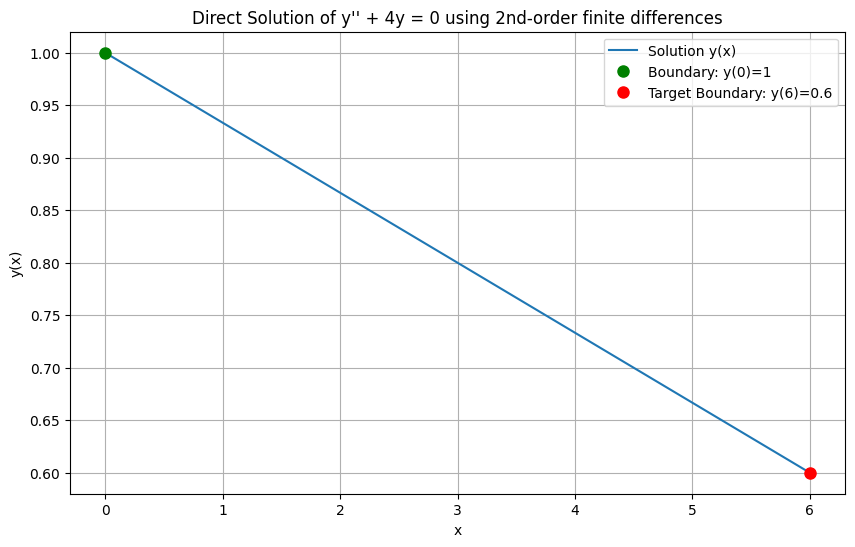

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# @title Activity 1A y''=0
a = 0 # @param {"type":"number"}
b = 6 # @param {"type":"number"}
alpha = 1 # @param {"type":"number"}
beta = 0.6 # @param {"type":"number"}
N = 10 # @param {"type":"number"}

def setup_bvp_ypp(a, b, alpha, beta, N):
    h = (b - a) / N
    n = N + 1  # include boundaries

    # Tridiagonal matrix A
    main = -2 * np.ones(n)
    off  = np.ones(n-1)

    # use diag to efficiently fill the bulk of th matrix
    A = np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

    # RHS vector b
    b_vec = np.zeros(n)

    # Left boundary: y_0 = alpha
    A[0, 0] = 1.0
    A[0, 1] = 0.
    b_vec[0] = alpha

    # Right boundary: y_N = beta
    A[N, N] = 1.0
    A[N, N-1] = 0.
    b_vec[N] = beta

    return A,b_vec

def solve_bvp(a,b,A,b_vec):
    n = len(b_vec)
    y = np.linalg.solve(A, b_vec)
    x = np.linspace(a, b, n)
    return x, y

# setup linear system
A,b_vec = setup_bvp_ypp(a, b, alpha, beta, N)

print("A = ",A)
print("b - ",b_vec)

x,y = solve_bvp(a,b,A,b_vec)

print("x = ",x)
print("y = ",y)

# Plot the converged solution
fig1 = plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Solution y(x)')
plt.plot(a, alpha, 'go', markersize=8, label=f'Boundary: y({a})={alpha}')
plt.plot(b, beta, 'ro', markersize=8, label=f'Target Boundary: y({b})={beta}')
plt.title("Direct Solution of y'' + 4y = 0 using 2nd-order finite differences")
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

In this case change the number of discretised points across the domain doesn't impact the solution as the result in this case is linear.

A more interesting example is that which appears in the notes $$y'' -4y=0$$

A =  [[ 1.      0.      0.     ...  0.      0.      0.    ]
 [ 1.     -1.9856  1.     ...  0.      0.      0.    ]
 [ 0.      1.     -1.9856 ...  0.      0.      0.    ]
 ...
 [ 0.      0.      0.     ... -1.9856  1.      0.    ]
 [ 0.      0.      0.     ...  1.     -1.9856  1.    ]
 [ 0.      0.      0.     ...  0.      0.      1.    ]]
b -  [1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.6]
x =  [0.   0.06 0.12 0.18 0.24 0.3  0.36 0.42 0.48 0.54 0.6  0.66 0.72 0.78
 0.84 0.9  0.96 1.02 1.08 1.14 1.2  1.26 1.32 1.38 1.44 1.5  1.56 1.62
 1.68 1.74 1.8  1.86 1.92 1.98 2.04 2.1  2.16 2.22 2.28 2.34 2.4  2.46
 2.52 2.58 2.64 2.7  2.76 2.82

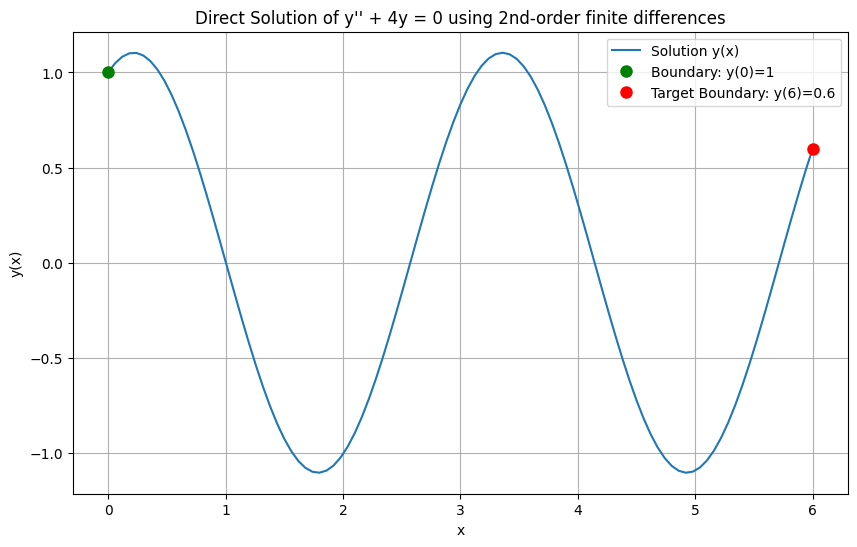

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# @title Activity 1A y''-4y=0
a = 0 # @param {"type":"number"}
b = 6 # @param {"type":"number"}
alpha = 1 # @param {"type":"number"}
beta = 0.6 # @param {"type":"number"}
N = 100 # @param {"type":"number"}

def setup_bvp_ypp_plus_4y(a, b, alpha, beta, N):
    h = (b - a) / N
    n = N + 1  # include boundaries

    # Tridiagonal matrix A
    main = (-2 + 4*h**2) * np.ones(n)
    off  = np.ones(n-1)

    # use diag to efficiently fill the bulk of th matrix
    A = np.diag(main) + np.diag(off, 1) + np.diag(off, -1)

    # RHS vector b
    b_vec = np.zeros(n)

    # Left boundary: y_0 = alpha
    A[0, 0] = 1.0
    A[0, 1] = 0.
    b_vec[0] = alpha

    # Right boundary: y_N = beta
    A[N, N] = 1.0
    A[N, N-1] = 0.
    b_vec[N] = beta

    return A,b_vec

def solve_bvp(a,b,A,b_vec):
    n = len(b_vec)
    y = np.linalg.solve(A, b_vec)
    x = np.linspace(a, b, n)
    return x, y

# setup linear system
A,b_vec = setup_bvp_ypp_plus_4y(a, b, alpha, beta, N)

print("A = ",A)
print("b - ",b_vec)

x,y = solve_bvp(a,b,A,b_vec)

print("x = ",x)
print("y = ",y)

# Plot the converged solution
fig1 = plt.figure(figsize=(10, 6))
plt.plot(x, y, label='Solution y(x)')
plt.plot(a, alpha, 'go', markersize=8, label=f'Boundary: y({a})={alpha}')
plt.plot(b, beta, 'ro', markersize=8, label=f'Target Boundary: y({b})={beta}')
plt.title("Direct Solution of y'' + 4y = 0 using 2nd-order finite differences")
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

## Activity 2A - Relaxation Method Solution




h = 0.6667
Number of total points = 10
Starting Jacobi Relaxation...
Iteration 0, Max Residual: 3.82e+00
Iteration 1000, Max Residual: 3.82e+00
Iteration 2000, Max Residual: 3.82e+00
Iteration 3000, Max Residual: 3.82e+00
Iteration 4000, Max Residual: 3.82e+00
Iteration 5000, Max Residual: 3.82e+00
Iteration 6000, Max Residual: 3.82e+00
Iteration 7000, Max Residual: 3.82e+00
Iteration 8000, Max Residual: 3.82e+00
Iteration 9000, Max Residual: 3.82e+00
Iteration 10000, Max Residual: 3.82e+00
Iteration 11000, Max Residual: 3.82e+00
Iteration 12000, Max Residual: 3.82e+00
Iteration 13000, Max Residual: 3.82e+00
Iteration 14000, Max Residual: 3.82e+00
Iteration 15000, Max Residual: 3.82e+00
Iteration 16000, Max Residual: 3.82e+00
Iteration 17000, Max Residual: 3.82e+00
Iteration 18000, Max Residual: 3.82e+00
Iteration 19000, Max Residual: 3.82e+00
Did not converge after 20000 iterations. Final Max residual: 3.82e+00


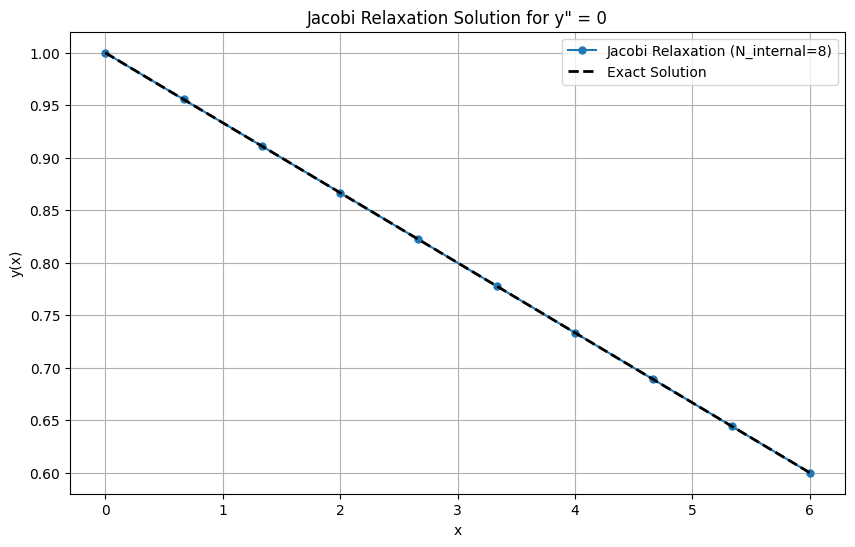

In [ ]:
# @title 💻 Jacobi Relaxation y''(0)
# @title Activity 1A y''-4y=0
a = 0 # @param {"type":"number"}
b = 6 # @param {"type":"number"}
alpha = 1 # @param {"type":"number"}
beta = 0.6 # @param {"type":"number"}
Npoints = 8 # @param {"type":"number"}

import numpy as np
import matplotlib.pyplot as plt

# Number of internal points (N_internal)
# Total points including boundaries will be N_internal + 2
# For Jacobi to converge with y'' = 0, h must be >= 1.
# h = (b-a) / (N_internal + 1). So (6-0) / (N_internal + 1) >= 1 => 6 >= N_internal + 1 => N_internal <= 5.
# Choosing N_internal = 3 to ensure h > 1 for clear convergence demonstration.
N_internal = Npoints # Reduced to ensure Jacobi convergence (h=1.5)
n_total = N_internal + 2 # Total points including boundaries

# Discretization
h = (b - a) / (n_total - 1)
x = np.linspace(a, b, n_total)

# Initial guess for y (linear interpolation between boundary conditions)
y = np.linspace(alpha, beta, n_total)

# Jacobi Relaxation parameters
max_iterations = 20000 # Increased max_iterations for potentially slow convergence
tolerance = 1e-7     # Adjusted tolerance for convergence

print(f"h = {h:.4f}")
print(f"Number of total points = {n_total}")

# Jacobi Relaxation loop
print("Starting Jacobi Relaxation...")
for iteration in range(max_iterations):
    y_old = np.copy(y) # Store previous iteration's values

    # Update internal points using the Jacobi formula
    # y_i = (y_{i+1} + y_{i-1}) / 2
    denominator = (2)
    if abs(denominator) < 1e-10: # Check for near-zero denominator
        print("Warning: Denominator in Jacobi formula is near zero. Adjust h or N_internal.")
        break

    for i in range(1, n_total - 1): # Iterate over internal points (excluding boundaries)
        y[i] = (y_old[i+1] + y_old[i-1]) / denominator

    # Calculate residual (using current y values for ODE check)
    # Note: Residuals are calculated using the updated 'y' for current iteration evaluation.
    residuals = np.zeros(N_internal)
    for i in range(1, n_total - 1):
        # R_i = (y(x_{i+1})-2y(x_i)+y(x_{i-1}))/h^2+4y(x_i)
        residuals[i-1] = (y[i+1] - 2*y[i] + y[i-1]) / h**2 + 4*y[i]

    max_residual = np.max(np.abs(residuals))

    if max_residual < tolerance:
        print(f"Converged after {iteration + 1} iterations. Max residual: {max_residual:.2e}")
        break

    if iteration % 1000 == 0: # Print progress periodically
        print(f"Iteration {iteration}, Max Residual: {max_residual:.2e}")

    if iteration == max_iterations - 1:
        print(f"Did not converge after {max_iterations} iterations. Final Max residual: {max_residual:.2e}")

import numpy as np

def exact_solution(x_val, a, b, alpha, beta):
    """
    Exact solution of y'' = 0 with y(a)=alpha, y(b)=beta.
    """
    C1 = (beta - alpha) / (b - a)
    C2 = alpha - C1 * a
    return C1 * x_val + C2

# Plot the solution
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Jacobi Relaxation (N_internal={N_internal})', marker='o', markersize=5, linestyle='-')

x_exact = np.linspace(a, b, 400)
plt.plot(x_exact, exact_solution(x_exact,a,b,alpha,beta), 'k--', linewidth=2, label="Exact Solution")

plt.title('Jacobi Relaxation Solution for y" = 0')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.grid(True)
plt.legend()
plt.show()


A more interesting case is $$y'' = 10$$, where the solution is not depedent of the number of internal points used to discretise the problem.

h = 0.0594
Number of total points = 102
Starting Jacobi Relaxation for y'' = 10...
Iteration 0, Max Residual: 1.00e+01
Iteration 1000, Max Residual: 7.79e+00
Iteration 2000, Max Residual: 4.83e+00
Iteration 3000, Max Residual: 2.98e+00
Iteration 4000, Max Residual: 1.84e+00
Iteration 5000, Max Residual: 1.13e+00
Iteration 6000, Max Residual: 6.98e-01
Iteration 7000, Max Residual: 4.30e-01
Iteration 8000, Max Residual: 2.65e-01
Iteration 9000, Max Residual: 1.63e-01
Iteration 10000, Max Residual: 1.01e-01
Iteration 11000, Max Residual: 6.21e-02
Iteration 12000, Max Residual: 3.83e-02
Iteration 13000, Max Residual: 2.36e-02
Iteration 14000, Max Residual: 1.45e-02
Iteration 15000, Max Residual: 8.97e-03
Iteration 16000, Max Residual: 5.53e-03
Iteration 17000, Max Residual: 3.41e-03
Iteration 18000, Max Residual: 2.10e-03
Iteration 19000, Max Residual: 1.29e-03
Did not converge after 20000 iterations. Final Max residual: 7.99e-04


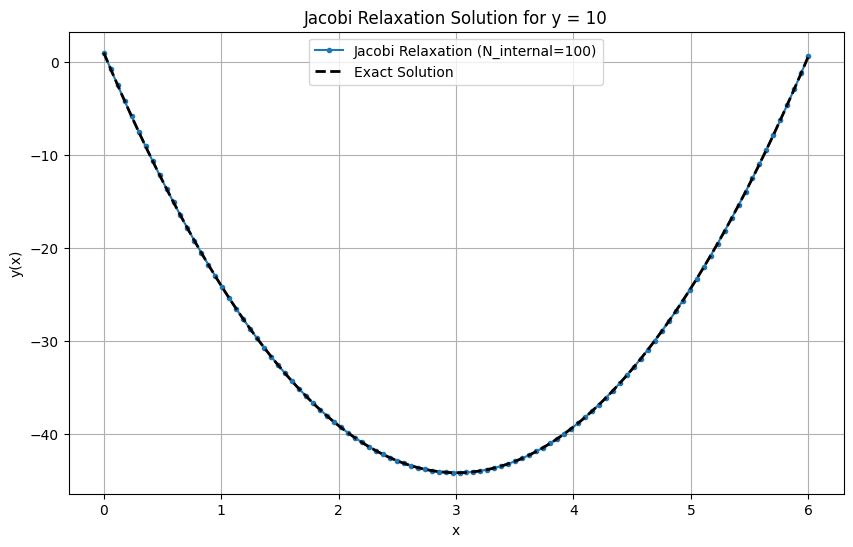

In [ ]:
# @title 💻 Jacobi Relaxation for y'' = 10
Npoints = 100 # @param {"type":"number","placeholder":"5"}
import numpy as np
import matplotlib.pyplot as plt

# Parameters for the BVP y'' = 10
a = 0.0
b = 6.0
alpha = 1.0  # y(0) = 1
beta = 0.6   # y(6) = 0.6

# Number of internal points (N_internal)
N_internal = Npoints
n_total = N_internal + 2 # Total points including boundaries

# Discretization
h = (b - a) / (n_total - 1)
x = np.linspace(a, b, n_total)

# Initial guess for y (linear interpolation between boundary conditions)
y = np.linspace(alpha, beta, n_total)

# Jacobi Relaxation parameters
max_iterations = 20000
tolerance = 1e-7

print(f"h = {h:.4f}")
print(f"Number of total points = {n_total}")

# Jacobi Relaxation loop
print("Starting Jacobi Relaxation for y'' = 10...")
for iteration in range(max_iterations):
    y_old = np.copy(y) # Store previous iteration's values

    # Update internal points using the Jacobi formula for y'' = 10
    # (y_{i+1} - 2y_i + y_{i-1}) / h**2 = 10
    # y_i = (y_{i+1} + y_{i-1} - 10 * h**2) / 2
    denominator = 2.0

    for i in range(1, n_total - 1): # Iterate over internal points (excluding boundaries)
        y[i] = (y_old[i+1] + y_old[i-1] - 10 * h**2) / denominator

    # Calculate residual for y'' = 10
    residuals = np.zeros(N_internal)
    for i in range(1, n_total - 1):
        residuals[i-1] = (y[i+1] - 2*y[i] + y[i-1]) / h**2 - 10

    max_residual = np.max(np.abs(residuals))

    if max_residual < tolerance:
        print(f"Converged after {iteration + 1} iterations. Max residual: {max_residual:.2e}")
        break

    if iteration % 1000 == 0: # Print progress periodically
        print(f"Iteration {iteration}, Max Residual: {max_residual:.2e}")

    if iteration == max_iterations - 1:
        print(f"Did not converge after {max_iterations} iterations. Final Max residual: {max_residual:.2e}")

# Exact solution for y'' = 10
def exact_solution_y10(x_val):
    # General solution: y = 5x^2 + C1x + C2
    # Apply boundary conditions y(0)=alpha, y(b)=beta
    C2 = alpha
    C1 = (beta - alpha - 5 * b**2) / b
    return 5 * x_val**2 + C1 * x_val + C2

# Plot the solution
plt.figure(figsize=(10, 6))
plt.plot(x, y, label=f'Jacobi Relaxation (N_internal={N_internal})', marker='o', markersize=3, linestyle='-')

x_exact = np.linspace(a, b, 400)
plt.plot(x_exact, exact_solution_y10(x_exact), 'k--', linewidth=2, label="Exact Solution")

plt.title('Jacobi Relaxation Solution for y'' = 10')
plt.xlabel('x')
plt.ylabel('y(x)')
plt.grid(True)
plt.legend()
plt.show()

## Activity 3A — Neural ODE

To better understand who this might work in practice, let's follow the example where an Neural ODE is used to try and learn the solution to the motion defined by the ODE
$$\frac{\mbox{d}x}{\mbox{d}t} = x^3 -x$$

The following Neural Network is trained on data for $x(t)$ that is obtained by a RK4 solution of this initial value problem.

The Loss used for the training is not based on a direct comparison of the learned ODE with the true ODE, as this approach is only useful when the underlying ODE is **unknown**.

If $x(t_f)$ is the solution that would come from the true ODE,

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f(t,x(t)) \mbox{d}t,$$

then the solution from the **Neural ODE** is

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f_\theta(t,x(t)) \mbox{d}t,$$

where $f_\theta$ is the output of a neural network with input $t$, and $x(t)$.

Forward solution of the system requires the temporal integration of output of the neural network, with loss based on the how well the resulting final position $x(t_f)$ matches the training data,

$$\mathcal{L}(x(t_f), y(t_f)).$$


We wil use PyTorch for this - one of the most popular libraries for NNs.

**Note**: The following Code can run on both CPU or Cuda GPUs. You can access free GPU's by changing the Colab runtime - but no this will not necessarily off a speed up for a small NN.

This is a relatively computationally intensive process, so we will limit our selves to 2 initial conditions and a time series of $t=[0,1]$ with 100 steps, for training.


Change `TODO_STEP_3A` to `[-0.9. -0.75, -0.5. -0.2, 0]` as initial condition, then explore how this affect the ability for the NN to generalise across different initial conditions - you may need to increase the epochs as you can mode initial contions to the network.

**Even with only three initial conditions this will take 10 mins or so!**



Using device: cpu
Epoch 0, Loss = 0.002481
Epoch 200, Loss = 0.000563
Epoch 400, Loss = 0.000117
Epoch 600, Loss = 0.000008
Epoch 800, Loss = 0.000007


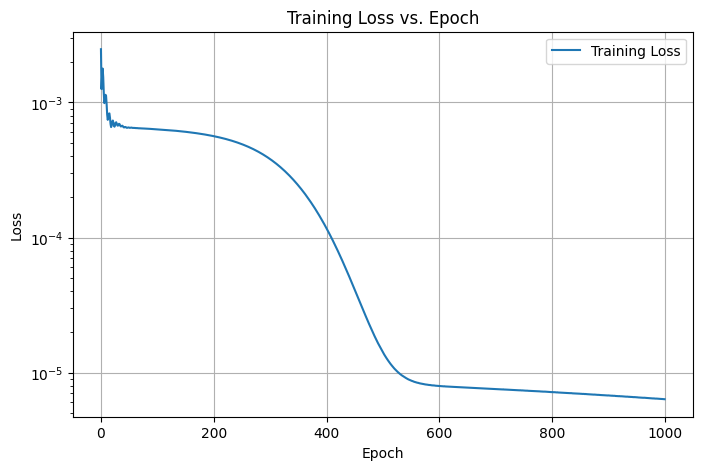

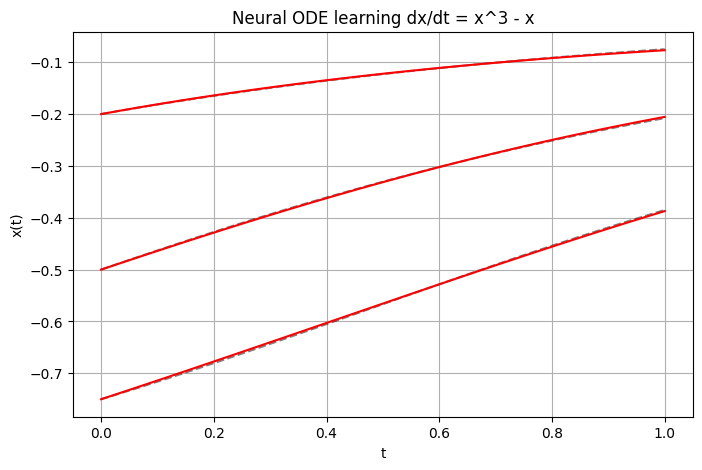

In [ ]:
!pip install torchdiffeq -q
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from torchdiffeq import odeint

TODO_STEP_3A=[-0.75, -0.5, -0.2] # increase to [-0.9. -0.75, -0.5. -0.2, 0]

# -----------------------------
# Select device
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.set_default_dtype(torch.float32)

# -----------------------------
# True ODE: dx/dt = x^3 - x
# -----------------------------
def f_true(t, x):
    return x**3 - x

# Generate training data
def generate_data(x0, T=3.0, steps=300):
    t = torch.linspace(0, T, steps, device=device)
    x = torch.zeros(steps, device=device)
    x[0] = x0
    dt = t[1] - t[0]
    for i in range(steps - 1):
        k1 = f_true(t[i], x[i])
        k2 = f_true(t[i] + dt/2, x[i] + dt*k1/2)
        k3 = f_true(t[i] + dt/2, x[i] + dt*k2/2)
        k4 = f_true(t[i] + dt,   x[i] + dt*k3)
        x[i+1] = x[i] + dt*(k1 + 2*k2 + 2*k3 + k4)/6
    return t, x

# Training dataset
ics = TODO_STEP_3A
data = [generate_data(torch.tensor(x0, device=device), T=1.0, steps=100) for x0 in ics]

# -----------------------------
# Neural ODE vector field
# -----------------------------
class ODEFunc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )
        for m in self.net:
            if isinstance(m, nn.Linear):
                #nn.init.uniform_(m.weight, -0.001, 0.001)
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, t, x):
        x = x.view(-1, 1)
        x = torch.clamp(x, -2.0, 2.0)
        out = self.net(x)
        #out = torch.clamp(out, -0.5, 0.5)
        return out.view(-1)

# this is a call to the ODE network that return the output
func = ODEFunc().to(device)

# -----------------------------
# Manual RK4 integrator
# -----------------------------
def integrate_nn(func, x0, t):
    xs = [x0]
    dt = t[1] - t[0]

    for i in range(len(t) - 1):
        x_i = xs[-1]

        k1 = func(t[i], x_i)
        k2 = func(t[i], x_i + dt*k1/2)
        k3 = func(t[i], x_i + dt*k2/2)
        k4 = func(t[i], x_i + dt*k3)

        x_next = x_i + dt*(k1 + 2*k2 + 2*k3 + k4)/6
        xs.append(x_next)

    return torch.stack(xs).squeeze()


# -----------------------------
# Training loop
# -----------------------------
optimizer = torch.optim.Adam(func.parameters(), lr=1e-3)
loss_history = [] # List to store loss values

for epoch in range(1000):
    loss = 0.0
    for t, x in data:
        x0 = x[0].unsqueeze(0)     # shape [1]

        #pred = integrate_nn(func, x0, t)
        # using func to obtain ODE estimate from the NN
        pred = odeint(func,x0,t,method='dopri5',rtol=1e-5,atol=1e-6).squeeze()

        if not torch.isfinite(pred).all():
            print("Non-finite in pred")
            print(pred[:10])
            raise RuntimeError("ODE produced non-finite values")

        loss += torch.mean((pred - x)**2)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(func.parameters(), max_norm=1.0)
    optimizer.step()

    loss_history.append(loss.item()) # Store the loss

    if epoch % 200 == 0:
        print(f"Epoch {epoch}, Loss = {loss.item():.6f}")

# -----------------------------
# Plotting Loss History
# -----------------------------
plt.figure(figsize=(8,5))
plt.plot(range(len(loss_history)), loss_history, label='Training Loss')
plt.title('Training Loss vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log') # Set y-axis to logarithmic scale
plt.grid(True)
plt.legend()
plt.show()

# -----------------------------
# Plotting (detach for numpy)
# -----------------------------
plt.figure(figsize=(8,5))
for t, x in data:
    x0 = x[0].unsqueeze(0)
    pred = integrate_nn(func, x0, t).detach().cpu()

    plt.plot(t.cpu().numpy(), x.cpu().numpy(), 'k--', alpha=0.5)
    plt.plot(t.cpu().numpy(), pred.numpy(), 'r')

plt.title("Neural ODE learning dx/dt = x^3 - x")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.grid(True)
plt.show()

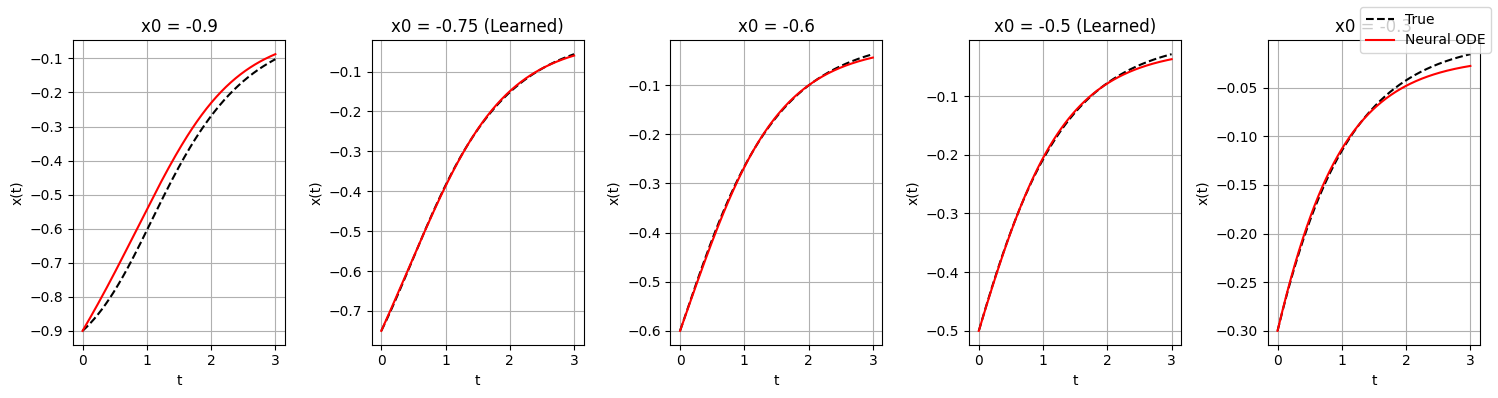

In [ ]:
# @title Test Solution with seen and unseen initial conditions -0.9, -0.75, -0.6, -0.5, -0.3
# test initial conditions x0
test_ics = [-0.9,-0.75, -0.6, -0.5, -0.3]

# generate test data - use the RK4 method contain in generate_date() from before
test_data = [generate_data(torch.tensor(x0, device=device), T=3.0, steps=200)
             for x0 in test_ics]

# generate predictions using the trained neural ODE.
# Create a row of 3 subplots
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

# Assuming TODO_STEP_3A contains the initial conditions used for training
learned_ics = TODO_STEP_3A

for ax, (x0, (t, x_true)) in zip(axes, zip(test_ics, test_data)):
    # Predict with Neural ODE
    x0_tensor = x_true[0].unsqueeze(0)
    x_pred = odeint(func, x0_tensor, t).squeeze().detach().cpu()

    # Plot true trajectory
    ax.plot(t.cpu(), x_true.cpu(), 'k--', label='True')

    # Plot NODE prediction
    ax.plot(t.cpu(), x_pred, 'r', label='Neural ODE')

    title_text = f"x0 = {x0}"
    if x0 in learned_ics:
        title_text += " (Learned)"
    ax.set_title(title_text)
    ax.set_xlabel("t")
    ax.set_ylabel("x(t)")
    ax.grid(True)

# Put legend only once (top‑right of figure)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')

plt.tight_layout()
plt.show()

See how well the NN learned the ODE

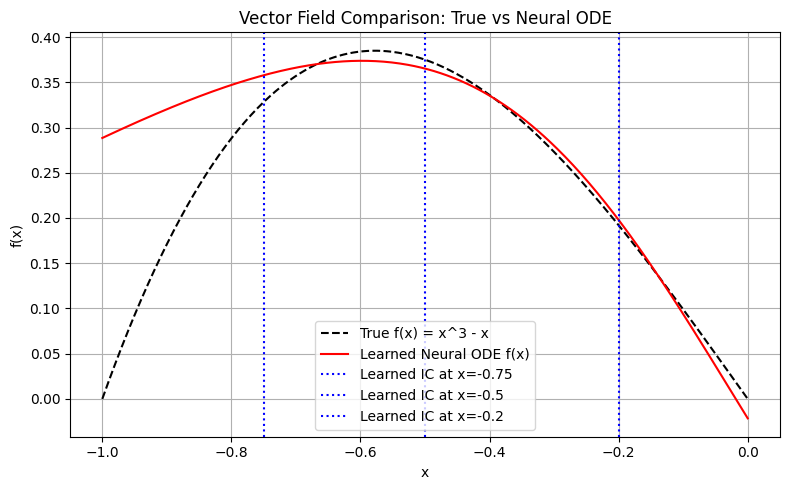

In [ ]:
# @title Evalutate the Learned ODE
import matplotlib.pyplot as plt

# Full domain to evaluate the vector field
xs = torch.linspace(-1.0, 0.0, 400, device=device)

# True vector field
f_true_vals = xs**3 - xs

# Learned vector field
f_pred_vals = func(None, xs).detach().cpu()

plt.figure(figsize=(8,5))

# Plot true derivative
plt.plot(xs.cpu(), f_true_vals.cpu(), 'k--', label='True f(x) = x^3 - x')

# Plot learned derivative
plt.plot(xs.cpu(), f_pred_vals, 'r', label='Learned Neural ODE f(x)')

# Mark learned initial conditions
# Assuming TODO_STEP_3A contains the initial conditions used for training
for ic in TODO_STEP_3A:
    plt.axvline(x=ic, color='blue', linestyle=':', linewidth=1.5, label=f'Learned IC at x={ic}')

plt.title("Vector Field Comparison: True vs Neural ODE")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Neural Network are slower to evaluate because of the need to solve the ODE at each training step, but can do a good job of learning the underlying dynamics in a way that plain NNs cannot.

We will come back to this in the Practical Class activities.

## Activity 4A — PINNs

Consider the motion of a dampled pendulum as governed by

$$ \theta''(t) + 2\beta \theta'(t) + \omega^2_0 \theta(t) = 0$$

with initial condition $\theta(0) = 2$ and $\theta'(0)$, i.e. as raised pendulum starting from a static state. $\omega_0$ is the undamped natural frequency of the system $\omega_0 = \sqrt{g/L}$ depends on gravity and the pendulum length, while $\beta$ is a dampling coefficient associated with friction in the system.

This example follows a case used by [Mathworks to describe the benefit of PINNs](https://au.mathworks.com/discovery/physics-informed-neural-networks.html). Based on their output we have estimated $\beta = 2.3$ and $\omega_0=20$.

`lambda_phys`, `lambda_ic` and `lambda_data` are weighting that determine how much loss contributes to overall loss used in trainig the NN.

Vary the weights associated with the each of the loss terms and see if you can explain what is happening.


In [ ]:
# @title PINN for θ''(t) + 2β θ'(t) + ω0² θ(t) = 0 (Fixed User Weights)

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# User-set weights
# ---------------------------------------------------------
lambda_phys = 0.0   # @param {"type":"number"}
lambda_ic   = 0.0   # @param {"type":"number"}
lambda_data = 1.0   # @param {"type":"number"}

# ---------------------------------------------------------
# 1. Neural Network for θ(t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, t):
        return self.net(t)

pinn = PINN().to(device)
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

# ---------------------------------------------------------
# ODE parameters
# ---------------------------------------------------------
beta = 2.3
omega0 = 20.0

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 500
t_f = torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial conditions θ(0)=θ0, θ'(0)=θ1
# ---------------------------------------------------------
theta0 = 2.0
theta1 = 0.0

t_ic = torch.zeros((1,1), device=device)

# ---------------------------------------------------------
# 4. Sensor data (synthetic)
# ---------------------------------------------------------
# analytical dampling coefficient
omega_d = np.sqrt(omega0**2 - beta**2)

C1 = theta0
C2 = (theta1 + beta * theta0) / omega_d

sensor_times = torch.linspace(0, 0.3, 6, device=device).unsqueeze(1)

t_np = sensor_times.cpu().numpy().flatten()

true_theta = np.exp(-beta * t_np) * (
    C1 * np.cos(omega_d * t_np) +
    C2 * np.sin(omega_d * t_np)
)

sensor_u = torch.tensor(true_theta, device=device).unsqueeze(1)


# ---------------------------------------------------------
# 5. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

loss_history = {"total": [], "phys": [], "ic": [], "data": []}

for epoch in range(5000):

    # Physics residual
    t_f.requires_grad_(True)
    theta = pinn(t_f)
    theta_t = gradients(theta, t_f)
    theta_tt = gradients(theta_t, t_f)

    R = theta_tt + 2*beta*theta_t + omega0**2 * theta
    L_phys = (R**2).mean()

    # Initial conditions
    t_ic.requires_grad_(True)
    L_ic = (pinn(t_ic) - theta0)**2 + (gradients(pinn(t_ic), t_ic) - theta1)**2

    # Sensor data
    u_pred = pinn(sensor_times)
    L_data = ((u_pred - sensor_u)**2).mean()

    # Weighted total loss
    loss = (
        lambda_phys * L_phys +
        lambda_ic   * L_ic +
        lambda_data * L_data
    )

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

Epoch 0, Loss=1.334237
Epoch 500, Loss=1.170917
Epoch 1000, Loss=1.109845
Epoch 1500, Loss=1.082566
Epoch 2000, Loss=1.001322
Epoch 2500, Loss=0.817077
Epoch 3000, Loss=0.485991
Epoch 3500, Loss=0.149683
Epoch 4000, Loss=0.025809
Epoch 4500, Loss=0.008751


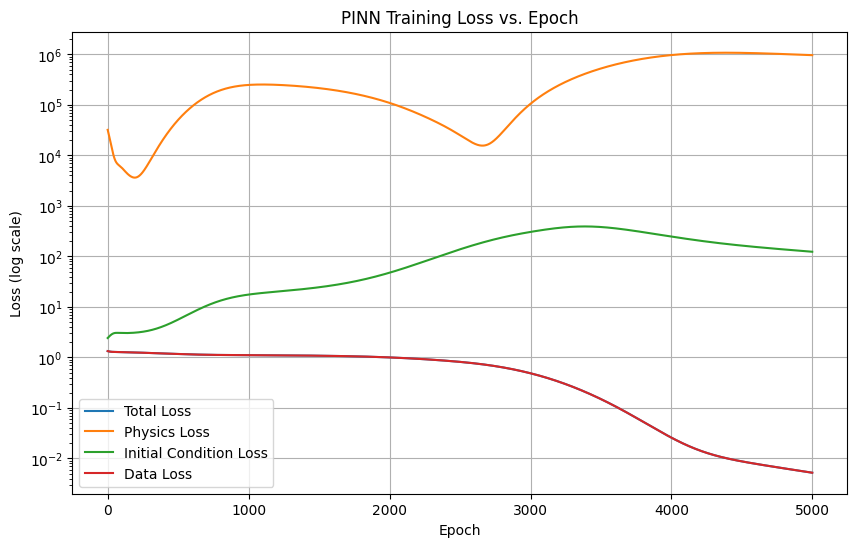

In [ ]:
# @title Plotting Loss History for PINN
# ---------------------------------------------------------
# Plotting Loss History for PINN
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(loss_history["total"], label='Total Loss')
plt.plot(loss_history["phys"], label='Physics Loss')
plt.plot(loss_history["ic"], label='Initial Condition Loss')
plt.plot(loss_history["data"], label='Data Loss')
plt.yscale('log') # Set y-axis to logarithmic scale
plt.title('PINN Training Loss vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.grid(True)
plt.legend()
plt.show()

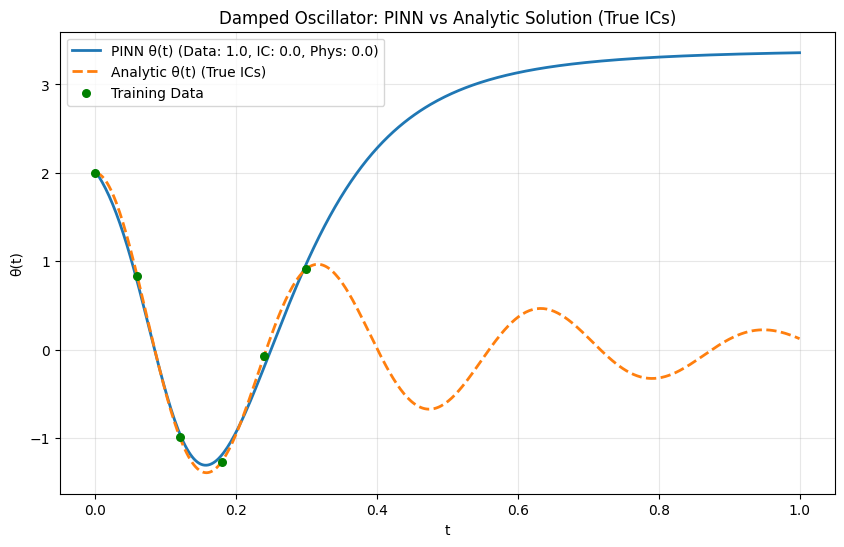

In [ ]:
# @title Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
# Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
t_plot = torch.linspace(0, 1, 400, device=device).unsqueeze(1)

# PINN prediction
theta_pinn = pinn(t_plot).detach().cpu().numpy().flatten()

# ---------------------------------------------------------
# Extract θ(0) and θ'(0) from the trained PINN
# ---------------------------------------------------------
t0 = torch.tensor([[0.0]], device=device, requires_grad=True)

theta0_pinn_val = pinn(t0)                      # θ(0) from PINN
theta0_pinn_item = theta0_pinn_val.item()

theta0_t_pinn_val = torch.autograd.grad(theta0_pinn_val, t0,
                               grad_outputs=torch.ones_like(theta0_pinn_val),
                               create_graph=False)[0]          # θ'(0) from PINN
theta1_pinn_item = theta0_t_pinn_val.item()

# ---------------------------------------------------------
# Compute analytic constants C1 and C2 using TRUE initial conditions
# ---------------------------------------------------------
# Explicitly set the true initial conditions to avoid any variable scope issues
true_ic_theta0 = 2.0 # From Activity 4A problem description
true_ic_theta1 = 0.0 # From Activity 4A problem description

# Ensure all components are standard Python floats or NumPy scalars before calculation
current_theta0 = float(true_ic_theta0)
current_theta1 = float(true_ic_theta1)
current_beta = float(beta)
current_omega_d = float(np.sqrt(omega0**2 - beta**2))

C1 = current_theta0
C2 = (current_theta1 + current_beta * current_theta0) / current_omega_d

# ---------------------------------------------------------
# Analytic solution using TRUE ICs
# ---------------------------------------------------------
t_np = t_plot.cpu().numpy().flatten()

theta_true = np.exp(-current_beta * t_np) * (
    C1 * np.cos(current_omega_d * t_np) +
    C2 * np.sin(current_omega_d * t_np)
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(t_np, theta_pinn, label=f"PINN θ(t) (Data: {lambda_data}, IC: {lambda_ic}, Phys: {lambda_phys})", linewidth=2)
plt.plot(t_np, theta_true, '--', label="Analytic θ(t) (True ICs)", linewidth=2)

# Training data points
plt.scatter(sensor_times.cpu().numpy(),
            sensor_u.cpu().numpy(),
            color='green', marker='o', s=30, zorder=5,
            label='Training Data')

plt.xlabel("t")
plt.ylabel("θ(t)")
plt.title("Damped Oscillator: PINN vs Analytic Solution (True ICs)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Try with Physics

In [ ]:
# @title PINN for θ''(t) + 2β θ'(t) + ω0² θ(t) = 0 (Fixed User Weights)

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# User-set weights
# ---------------------------------------------------------
lambda_phys = 1.0   # @param {"type":"number"}
lambda_ic   = 1.0   # @param {"type":"number"}
lambda_data = 1.0   # @param {"type":"number"}

# ---------------------------------------------------------
# 1. Neural Network for θ(t)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, t):
        return self.net(t)

pinn = PINN().to(device)
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

# ---------------------------------------------------------
# ODE parameters
# ---------------------------------------------------------
beta = 2.3
omega0 = 20.0

# ---------------------------------------------------------
# 2. Collocation points (physics)
# ---------------------------------------------------------
N_f = 1000
t_f = 0.3*torch.rand(N_f, 1, device=device)

# ---------------------------------------------------------
# 3. Initial conditions θ(0)=θ0, θ'(0)=θ1
# ---------------------------------------------------------
theta0 = 2.0
theta1 = 0.0

t_ic = torch.zeros((1,1), device=device, requires_grad=True)

# ---------------------------------------------------------
# 4. Sensor data (synthetic)
# ---------------------------------------------------------
# analytical dampling coefficient
omega_d = np.sqrt(omega0**2 - beta**2)

C1 = theta0
C2 = (theta1 + beta * theta0) / omega_d

sensor_times = torch.linspace(0, 0.3, 6, device=device).unsqueeze(1)

t_np = sensor_times.cpu().numpy().flatten()

true_theta = np.exp(-beta * t_np) * (
    C1 * np.cos(omega_d * t_np) +
    C2 * np.sin(omega_d * t_np)
)
sensor_u = torch.tensor(true_theta, device=device).unsqueeze(1)


# ---------------------------------------------------------
# 5. Training loop
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u),
                               create_graph=True)[0]

loss_history = {"total": [], "phys": [], "ic": [], "data": []}

for epoch in range(5000):

    # Physics residual
    t_f.requires_grad_(True)
    theta = pinn(t_f)
    theta_t = gradients(theta, t_f)
    theta_tt = gradients(theta_t, t_f)

    R = theta_tt + 2*beta*theta_t + omega0**2 * theta
    L_phys = (R**2).mean()

    # Initial conditions
    t_ic.requires_grad_(True)
    L_ic = (pinn(t_ic) - theta0)**2 + (gradients(pinn(t_ic), t_ic) - theta1)**2

    #print(epoch,t_ic,pinn(t_ic).item(), gradients(pinn(t_ic), t_ic).item())

    # Sensor data
    u_pred = pinn(sensor_times)
    L_data = ((u_pred - sensor_u)**2).mean()

    # Weighted total loss
    loss = (
        lambda_phys * L_phys +
        lambda_ic   * L_ic +
        lambda_data * L_data
    )

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")

Epoch 0, Loss=1058.089966
Epoch 500, Loss=5.349185
Epoch 1000, Loss=5.349169
Epoch 1500, Loss=5.349144
Epoch 2000, Loss=5.349112
Epoch 2500, Loss=5.349069
Epoch 3000, Loss=5.349019
Epoch 3500, Loss=5.348960
Epoch 4000, Loss=5.348893
Epoch 4500, Loss=5.348822


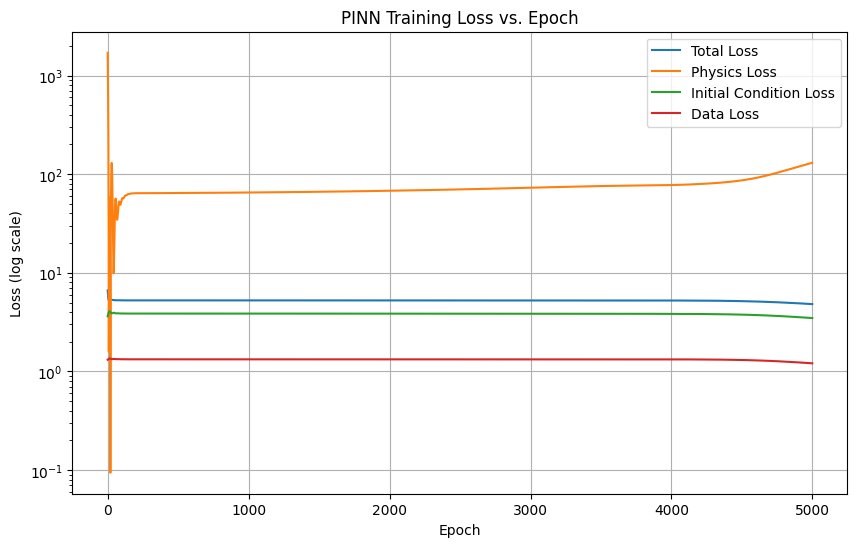

In [ ]:
# @title Plotting Loss History for PINN
# ---------------------------------------------------------
# Plotting Loss History for PINN
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(loss_history["total"], label='Total Loss')
plt.plot(loss_history["phys"], label='Physics Loss')
plt.plot(loss_history["ic"], label='Initial Condition Loss')
plt.plot(loss_history["data"], label='Data Loss')
plt.yscale('log') # Set y-axis to logarithmic scale
plt.title('PINN Training Loss vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.grid(True)
plt.legend()
plt.show()

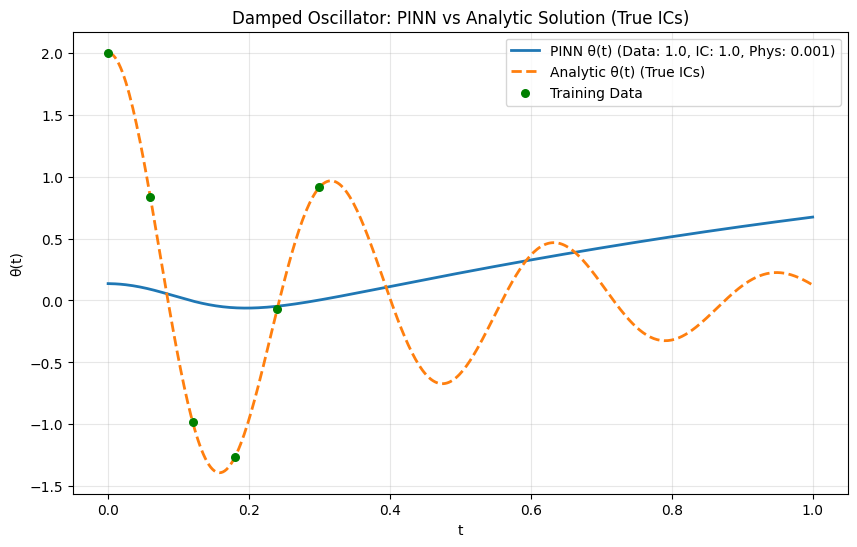

In [ ]:
# @title Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
# Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
t_plot = torch.linspace(0, 1, 400, device=device).unsqueeze(1)

# PINN prediction
theta_pinn = pinn(t_plot).detach().cpu().numpy().flatten()

# ---------------------------------------------------------
# Extract θ(0) and θ'(0) from the trained PINN
# ---------------------------------------------------------
t0 = torch.tensor([[0.0]], device=device, requires_grad=True)

theta0_pinn_val = pinn(t0)                      # θ(0) from PINN
theta0_pinn_item = theta0_pinn_val.item()

theta0_t_pinn_val = torch.autograd.grad(theta0_pinn_val, t0,
                               grad_outputs=torch.ones_like(theta0_pinn_val),
                               create_graph=False)[0]          # θ'(0) from PINN
theta1_pinn_item = theta0_t_pinn_val.item()

# ---------------------------------------------------------
# Compute analytic constants C1 and C2 using TRUE initial conditions
# ---------------------------------------------------------
# Explicitly set the true initial conditions to avoid any variable scope issues
true_ic_theta0 = 2.0 # From Activity 4A problem description
true_ic_theta1 = 0.0 # From Activity 4A problem description

# Ensure all components are standard Python floats or NumPy scalars before calculation
current_theta0 = float(true_ic_theta0)
current_theta1 = float(true_ic_theta1)
current_beta = float(beta)
current_omega_d = float(np.sqrt(omega0**2 - beta**2))

C1 = current_theta0
C2 = (current_theta1 + current_beta * current_theta0) / current_omega_d

# ---------------------------------------------------------
# Analytic solution using TRUE ICs
# ---------------------------------------------------------
t_np = t_plot.cpu().numpy().flatten()

theta_true = np.exp(-current_beta * t_np) * (
    C1 * np.cos(current_omega_d * t_np) +
    C2 * np.sin(current_omega_d * t_np)
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(t_np, theta_pinn, label=f"PINN θ(t) (Data: {lambda_data}, IC: {lambda_ic}, Phys: {lambda_phys})", linewidth=2)
plt.plot(t_np, theta_true, '--', label="Analytic θ(t) (True ICs)", linewidth=2)

# Training data points
plt.scatter(sensor_times.cpu().numpy(),
            sensor_u.cpu().numpy(),
            color='green', marker='o', s=30, zorder=5,
            label='Training Data')

plt.xlabel("t")
plt.ylabel("θ(t)")
plt.title("Damped Oscillator: PINN vs Analytic Solution (True ICs)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

This is a common problem with PINNs when Physics has a residual whose scale is far greater than the data.

Consider the original ODE in physical time `t`
$$ \theta^{\prime\prime}(t) + 2\beta\,\theta^\prime(t) + \omega_0^2\,\theta(t) = 0.
$$
The problem is that the term
$$ \omega_0^2 = 400
$$
is huge compared to the others, which makes the physics residual extremely large.

We fix this by non-dimensionalizing time.
> This process needs to be done carefully as anychange in variable may require a change in initial conditions and a rescaling of input data.
> * The difficult part is realising you need to rescale the problem and recognition that you can do so my via the time.
> * the advantage of scaling in time is that we don't need to scale $\theta$.
---
1. Define a dimensionless time variable
Let
$$\tau = \omega_0 t.$$

    This rescales time so that one undampled oscillation period is $\mathcal{O}(1) $ instead of $ \mathcal{O}(0.05) $.

2. Compute how derivatives transform

    We need to express derivatives with respect to $ t $ in terms of derivatives with respect to $ \tau $.

$$ \frac{d\theta}{dt}
= \frac{d\theta}{d\tau}\frac{d\tau}{dt}
= \omega_0\,\frac{d\theta}{d\tau}.
$$

$$ \theta^\prime(t) = \omega_0\,\theta_\tau.$$

3. Differentiate again:

$$ \theta^{\prime\prime}(t)
= \frac{d}{dt}\left(\omega_0\,\theta_\tau\right)
= \omega_0\,\frac{d\theta_\tau}{dt}.
$$
But:
$$ \frac{d\theta_\tau}{dt}
= \frac{d\theta_\tau}{d\tau}\frac{d\tau}{dt}
= \theta_{\tau\tau}\,\omega_0.
$$
Thus:
$$\theta^{\prime\prime}(t) = \omega_0^2\,\theta_{\tau\tau}.$$

4. Substitute into the original ODE
Original:
$$ \theta^{\prime\prime}(t) + 2\beta\,\theta^\prime(t) + \omega_0^2\theta = 0.
$$
Replace derivatives:
$$ \omega_0^2\,\theta_{\tau\tau}
+ 2\beta\,(\omega_0\,\theta_\tau)
+ \omega_0^2\,\theta = 0.
 $$
5. Factor out $ \omega_0^2 $:
$$ \omega_0^2\left[
\theta_{\tau\tau}
+ 2\frac{\beta}{\omega_0}\theta_\tau
+ \theta
\right] = 0.$$

6. Get Non-dimensional form
$$ \theta_{\tau\tau}
+ 2\frac{\beta}{\omega_0}\theta_\tau
+ \theta = 0.
$$

7. Define the dimensionless damping coefficient
$$ \tilde{\beta} = \frac{\beta}{\omega_0}.
$$
For our parameters:
$$ \beta = 2.3,\quad \omega_0 = 20
\quad\Rightarrow\quad
\tilde{\beta} = 0.115.
$$
Thus the ODE becomes:
$$ \theta_{\tau\tau} + 0.23\,\theta_\tau + \theta = 0.
$$
All coefficients are now order 1, which is exactly what we want.

8. Rescaled initial conditions
Original ICs:
$$ \theta(0) = \theta_0,\qquad \theta^\prime(0) = \theta_1.
$$
But:
$$ \theta^\prime(0) = \omega_0\,\theta_\tau(0)
\quad\Rightarrow\quad
\theta_\tau(0) = \frac{\theta_1}{\omega_0}.
$$
For our case:
$$ \theta_1 = 0 \quad\Rightarrow\quad \theta_\tau(0) = 0.
$$
So the ICs in $\tau$‑space are:
$$ \theta(0) = 2,\qquad \theta_\tau(0) = 0.
$$

9. Rescaling the sensor data
If sensor data are at physical times $ t_j $, convert them to $\tau$:
$$ \tau_j = \omega_0 t_j.
$$
The measured angles $ \theta_j $ do not change.
Thus the data loss becomes:
$$ L_{\text{data}}
= \frac{1}{N}\sum_j (\theta_{\text{NN}}(\tau_j) - \theta_j)^2.
$$

10. Final dimensionless PINN residual
$$ R(\tau)
= \theta_{\tau\tau}
+ 2\tilde{\beta}\,\theta_\tau
+ \theta.
$$
Physics loss:
$$ L_{\text{phys}} = \frac{1}{N}\sum R(\tau_i)^2.
$$
This is now naturally $ \mathcal{O}(1) $, not $\mathcal{O}(10^2)$.

In [ ]:
# @title PINN for θ''(t) + 2β θ'(t) + ω0² θ(t) = 0 rescaled
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# User-set weights
# ---------------------------------------------------------
lambda_phys = 1.0 # @param {"type":"number"}
lambda_ic   = 1.0 # @param {"type":"number"}
lambda_data = 1.0 # @param {"type":"number"}

# ---------------------------------------------------------
# 1. Neural Network for θ(τ)
# ---------------------------------------------------------
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, tau):
        return self.net(tau)

pinn = PINN().to(device)
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

# ---------------------------------------------------------
# ODE parameters (physical)
# ---------------------------------------------------------
beta = 2.3
omega0 = 20.0

# Dimensionless damping
beta_tilde = beta / omega0

# ---------------------------------------------------------
# 2. Collocation points (physics) in τ-space
# ---------------------------------------------------------
N_f = 2000

# 50% in [0, 0.3]
t_f1 = 0.3 * torch.rand(int(0.5 * N_f), 1, device=device)

# 50% in [0.3, 1.0]
t_f2 = 0.3 + (1.0 - 0.3) * torch.rand(int(0.5 * N_f), 1, device=device)

t_f = torch.cat([t_f1, t_f2], dim=0)
tau_f = omega0 * t_f



# ---------------------------------------------------------
# 3. Initial conditions θ(0)=θ0, θ'(0)=θ1
# ---------------------------------------------------------
theta0 = 2.0
theta1 = 0.0

tau_ic = torch.zeros((1,1), device=device, requires_grad=True)

# ---------------------------------------------------------
# 4. Sensor data (synthetic)
# ---------------------------------------------------------
omega_d = np.sqrt(omega0**2 - beta**2)

C1 = theta0
C2 = (theta1 + beta * theta0) / omega_d

sensor_times = torch.linspace(0, 0.3, 6, device=device).unsqueeze(1)
sensor_tau = omega0 * sensor_times  # convert to τ

t_np = sensor_times.cpu().numpy().flatten()

true_theta = np.exp(-beta * t_np) * (
    C1 * np.cos(omega_d * t_np) +
    C2 * np.sin(omega_d * t_np)
)
sensor_u = torch.tensor(true_theta, device=device).unsqueeze(1)

# ---------------------------------------------------------
# Helper: gradients
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(
        u, x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

# ---------------------------------------------------------
# Physics residual in τ-space
# ---------------------------------------------------------
def physics_residual(model, tau):
    tau.requires_grad_(True)

    theta = model(tau)
    dtheta_dtau = gradients(theta, tau)
    d2theta_dtau2 = gradients(dtheta_dtau, tau)

    # Dimensionless ODE: θ'' + 2β̃ θ' + θ = 0
    R = d2theta_dtau2 + 2*beta_tilde*dtheta_dtau + theta
    return R

# ---------------------------------------------------------
# 5. Training loop
# ---------------------------------------------------------
loss_history = {"total": [], "phys": [], "ic": [], "data": []}

for epoch in range(20000):

    # Physics loss
    R = physics_residual(pinn, tau_f)
    L_phys = (R**2).mean()

    # Initial condition loss
    tau_ic.requires_grad_(True)
    theta_ic = pinn(tau_ic)
    dtheta_ic = gradients(theta_ic, tau_ic)

    # θ'(t) = ω0 θ_τ  →  θ_τ(0) = θ'(0)/ω0 = 0
    L_ic = (theta_ic - theta0)**2 + (dtheta_ic - 0.0)**2

    # Data loss
    u_pred = pinn(sensor_tau)
    L_data = ((u_pred - sensor_u)**2).mean()

    # Weighted total loss
    loss = (
        lambda_phys * L_phys +
        lambda_ic   * L_ic +
        lambda_data * L_data
    )

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")


Epoch 0, Loss=5.976617
Epoch 500, Loss=0.816605
Epoch 1000, Loss=0.567952
Epoch 1500, Loss=0.445466
Epoch 2000, Loss=0.339851
Epoch 2500, Loss=0.251991
Epoch 3000, Loss=0.174800
Epoch 3500, Loss=0.123024
Epoch 4000, Loss=0.093416
Epoch 4500, Loss=0.075858
Epoch 5000, Loss=0.064247
Epoch 5500, Loss=0.055594
Epoch 6000, Loss=0.048693
Epoch 6500, Loss=0.043119
Epoch 7000, Loss=0.037834
Epoch 7500, Loss=0.033628
Epoch 8000, Loss=0.027315
Epoch 8500, Loss=0.021489
Epoch 9000, Loss=0.018000
Epoch 9500, Loss=0.016129
Epoch 10000, Loss=0.014945
Epoch 10500, Loss=0.014081
Epoch 11000, Loss=0.013485
Epoch 11500, Loss=0.012969
Epoch 12000, Loss=0.012577
Epoch 12500, Loss=0.012215
Epoch 13000, Loss=0.011865
Epoch 13500, Loss=0.011529
Epoch 14000, Loss=0.011254
Epoch 14500, Loss=0.010949
Epoch 15000, Loss=0.010632
Epoch 15500, Loss=0.009872
Epoch 16000, Loss=0.008750
Epoch 16500, Loss=0.007852
Epoch 17000, Loss=0.007194
Epoch 17500, Loss=0.006768
Epoch 18000, Loss=0.006501
Epoch 18500, Loss=0.00631

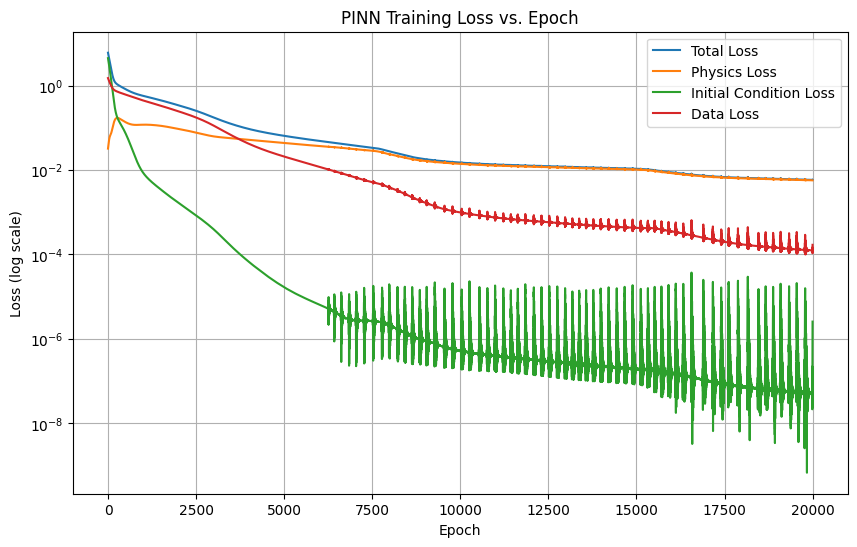

In [ ]:
# @title Plotting Loss History for PINN
# ---------------------------------------------------------
# Plotting Loss History for PINN
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(loss_history["total"], label='Total Loss')
plt.plot(loss_history["phys"], label='Physics Loss')
plt.plot(loss_history["ic"], label='Initial Condition Loss')
plt.plot(loss_history["data"], label='Data Loss')
plt.yscale('log') # Set y-axis to logarithmic scale
plt.title('PINN Training Loss vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.grid(True)
plt.legend()
plt.show()

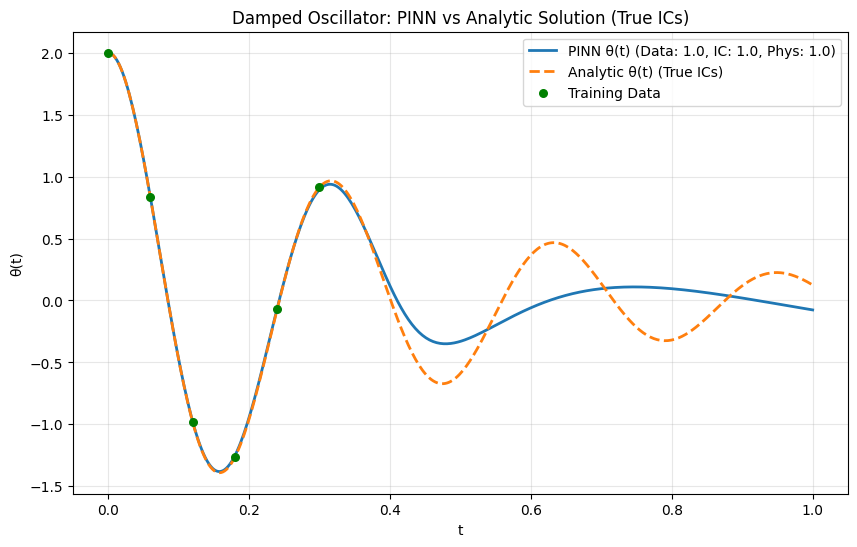

In [ ]:
# @title Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
# Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
t_plot = torch.linspace(0, 1, 400, device=device).unsqueeze(1)

# PINN prediction
# rescale time
tau_plot = omega0 * t_plot
theta_pinn = pinn(tau_plot).detach().cpu().numpy().flatten()

# Correct IC extraction in rescaled PINN
tau0 = torch.tensor([[0.0]], device=device, requires_grad=True)

theta0_pinn_val = pinn(tau0)
dtheta_dtau = torch.autograd.grad(
    theta0_pinn_val, tau0,
    grad_outputs=torch.ones_like(theta0_pinn_val),
    create_graph=False
)[0]

theta0_pinn_item = theta0_pinn_val.item()
theta1_pinn_item = (omega0 * dtheta_dtau).item()   # dimensional derivative

# ---------------------------------------------------------
# Compute analytic constants C1 and C2 using TRUE initial conditions
# ---------------------------------------------------------
# Explicitly set the true initial conditions to avoid any variable scope issues
true_ic_theta0 = 2.0 # From Activity 4A problem description
true_ic_theta1 = 0.0 # From Activity 4A problem description

# Ensure all components are standard Python floats or NumPy scalars before calculation
current_theta0 = float(true_ic_theta0)
current_theta1 = float(true_ic_theta1)
current_beta = float(beta)
current_omega_d = float(np.sqrt(omega0**2 - beta**2))

C1 = current_theta0
C2 = (current_theta1 + current_beta * current_theta0) / current_omega_d

# ---------------------------------------------------------
# Analytic solution using TRUE ICs
# ---------------------------------------------------------
t_np = t_plot.cpu().numpy().flatten()

theta_true = np.exp(-current_beta * t_np) * (
    C1 * np.cos(current_omega_d * t_np) +
    C2 * np.sin(current_omega_d * t_np)
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(t_np, theta_pinn, label=f"PINN θ(t) (Data: {lambda_data}, IC: {lambda_ic}, Phys: {lambda_phys})", linewidth=2)
plt.plot(t_np, theta_true, '--', label="Analytic θ(t) (True ICs)", linewidth=2)

# Training data points
plt.scatter(sensor_times.cpu().numpy(),
            sensor_u.cpu().numpy(),
            color='green', marker='o', s=30, zorder=5,
            label='Training Data')

plt.xlabel("t")
plt.ylabel("θ(t)")
plt.title("Damped Oscillator: PINN vs Analytic Solution (True ICs)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

No data beyond t=0.3, so physics may cause solution to decay to trival solution $\theta = 0$ too soon.

In [ ]:
# @title PINN for θ''(t) + 2β θ'(t) + ω0² θ(t) = 0 rescaled with Sin activation
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# User-set weights
# ---------------------------------------------------------
lambda_phys = 1.0 # @param {"type":"number"}
lambda_ic   = 1.0 # @param {"type":"number"}
lambda_data = 1.0 # @param {"type":"number"}


# ---------------------------------------------------------
# 1. Neural Network for θ(τ)
# ---------------------------------------------------------

class Sin(nn.Module):
    def forward(self, x):
        return torch.sin(x)

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64),
            Sin(),
            nn.Linear(64, 64),
            Sin(),
            nn.Linear(64, 1)
        )

    def forward(self, tau):
        return self.net(tau)

pinn = PINN().to(device)
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-4)

# ---------------------------------------------------------
# ODE parameters (physical)
# ---------------------------------------------------------
beta = 2.3
omega0 = 20.0

# Dimensionless damping
beta_tilde = beta / omega0

# ---------------------------------------------------------
# 2. Collocation points (physics) in τ-space
# ---------------------------------------------------------
N_f = 2000

# 50% in [0, 0.3]
t_f1 = 0.3 * torch.rand(int(0.5 * N_f), 1, device=device)

# 50% in [0.3, 1.0]
t_f2 = 0.3 + (1.0 - 0.3) * torch.rand(int(0.5 * N_f), 1, device=device)

t_f = torch.cat([t_f1, t_f2], dim=0)
tau_f = omega0 * t_f



# ---------------------------------------------------------
# 3. Initial conditions θ(0)=θ0, θ'(0)=θ1
# ---------------------------------------------------------
theta0 = 2.0
theta1 = 0.0

tau_ic = torch.zeros((1,1), device=device, requires_grad=True)

# ---------------------------------------------------------
# 4. Sensor data (synthetic)
# ---------------------------------------------------------
omega_d = np.sqrt(omega0**2 - beta**2)

C1 = theta0
C2 = (theta1 + beta * theta0) / omega_d

sensor_times = torch.linspace(0, 0.3, 6, device=device).unsqueeze(1)
sensor_tau = omega0 * sensor_times  # convert to τ

t_np = sensor_times.cpu().numpy().flatten()

true_theta = np.exp(-beta * t_np) * (
    C1 * np.cos(omega_d * t_np) +
    C2 * np.sin(omega_d * t_np)
)
sensor_u = torch.tensor(true_theta, device=device).unsqueeze(1)

# ---------------------------------------------------------
# Helper: gradients
# ---------------------------------------------------------
def gradients(u, x):
    return torch.autograd.grad(
        u, x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

# ---------------------------------------------------------
# Physics residual in τ-space
# ---------------------------------------------------------
def physics_residual(model, tau):
    tau.requires_grad_(True)

    theta = model(tau)
    dtheta_dtau = gradients(theta, tau)
    d2theta_dtau2 = gradients(dtheta_dtau, tau)

    # Dimensionless ODE: θ'' + 2β̃ θ' + θ = 0
    R = d2theta_dtau2 + 2*beta_tilde*dtheta_dtau + theta
    return R

# ---------------------------------------------------------
# 5. Training loop
# ---------------------------------------------------------
loss_history = {"total": [], "phys": [], "ic": [], "data": []}

for epoch in range(10000):

    # Physics loss
    R = physics_residual(pinn, tau_f)
    L_phys = (R**2).mean()

    # Initial condition loss
    tau_ic.requires_grad_(True)
    theta_ic = pinn(tau_ic)
    dtheta_ic = gradients(theta_ic, tau_ic)

    # θ'(t) = ω0 θ_τ  →  θ_τ(0) = θ'(0)/ω0 = 0
    L_ic = (theta_ic - theta0)**2 + (dtheta_ic - 0.0)**2

    # Data loss
    u_pred = pinn(sensor_tau)
    L_data = ((u_pred - sensor_u)**2).mean()

    # Weighted total loss
    loss = (
        lambda_phys * L_phys +
        lambda_ic   * L_ic +
        lambda_data * L_data
    )

    loss_history["total"].append(loss.item())
    loss_history["phys"].append(L_phys.item())
    loss_history["ic"].append(L_ic.item())
    loss_history["data"].append(L_data.item())

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss={loss.item():.6f}")


Epoch 0, Loss=4.652440
Epoch 500, Loss=0.098649
Epoch 1000, Loss=0.009279
Epoch 1500, Loss=0.004023
Epoch 2000, Loss=0.001650
Epoch 2500, Loss=0.000630
Epoch 3000, Loss=0.000218
Epoch 3500, Loss=0.000097
Epoch 4000, Loss=0.000069
Epoch 4500, Loss=0.000055
Epoch 5000, Loss=0.000044
Epoch 5500, Loss=0.000036
Epoch 6000, Loss=0.000029
Epoch 6500, Loss=0.000023
Epoch 7000, Loss=0.000018
Epoch 7500, Loss=0.000014
Epoch 8000, Loss=0.000010
Epoch 8500, Loss=0.000008
Epoch 9000, Loss=0.000005
Epoch 9500, Loss=0.000004
Epoch 10000, Loss=0.000003
Epoch 10500, Loss=0.000003
Epoch 11000, Loss=0.000002
Epoch 11500, Loss=0.000002
Epoch 12000, Loss=0.000001
Epoch 12500, Loss=0.000001
Epoch 13000, Loss=0.000001
Epoch 13500, Loss=0.000001
Epoch 14000, Loss=0.000001
Epoch 14500, Loss=0.000001
Epoch 15000, Loss=0.000001
Epoch 15500, Loss=0.000001
Epoch 16000, Loss=0.000000
Epoch 16500, Loss=0.000000
Epoch 17000, Loss=0.000000
Epoch 17500, Loss=0.000000
Epoch 18000, Loss=0.000000
Epoch 18500, Loss=0.00000

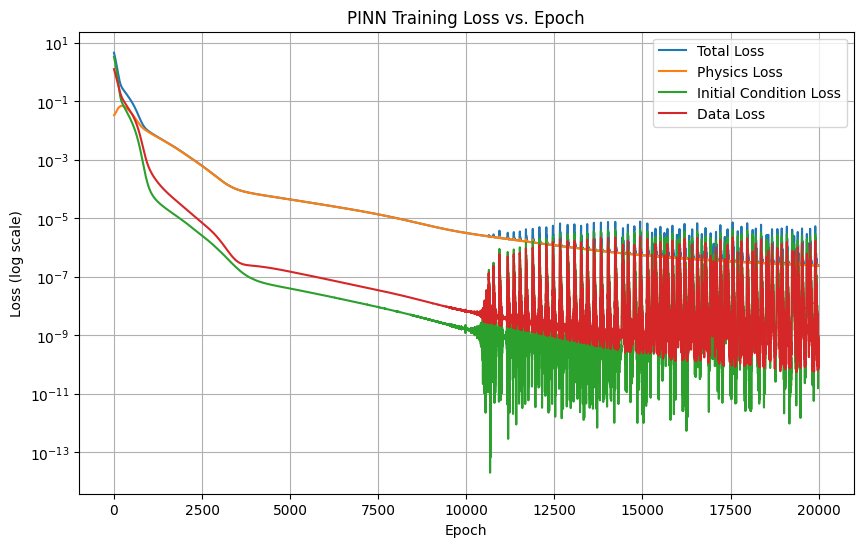

In [ ]:
# @title Plotting Loss History for PINN
# ---------------------------------------------------------
# Plotting Loss History for PINN
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(loss_history["total"], label='Total Loss')
plt.plot(loss_history["phys"], label='Physics Loss')
plt.plot(loss_history["ic"], label='Initial Condition Loss')
plt.plot(loss_history["data"], label='Data Loss')
plt.yscale('log') # Set y-axis to logarithmic scale
plt.title('PINN Training Loss vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss (log scale)')
plt.grid(True)
plt.legend()
plt.show()

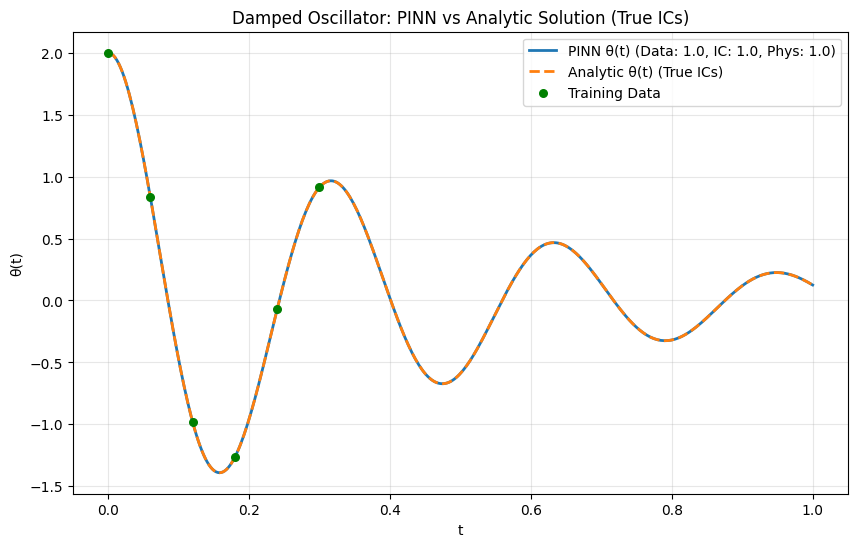

In [ ]:
# @title Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
# Plot θ(t) vs t: PINN vs Analytic (with adaptive ICs)
# ---------------------------------------------------------
t_plot = torch.linspace(0, 1, 400, device=device).unsqueeze(1)

# PINN prediction
# rescale time
tau_plot = omega0 * t_plot
theta_pinn = pinn(tau_plot).detach().cpu().numpy().flatten()

# Correct IC extraction in rescaled PINN
tau0 = torch.tensor([[0.0]], device=device, requires_grad=True)

theta0_pinn_val = pinn(tau0)
dtheta_dtau = torch.autograd.grad(
    theta0_pinn_val, tau0,
    grad_outputs=torch.ones_like(theta0_pinn_val),
    create_graph=False
)[0]

theta0_pinn_item = theta0_pinn_val.item()
theta1_pinn_item = (omega0 * dtheta_dtau).item()   # dimensional derivative

# ---------------------------------------------------------
# Compute analytic constants C1 and C2 using TRUE initial conditions
# ---------------------------------------------------------
# Explicitly set the true initial conditions to avoid any variable scope issues
true_ic_theta0 = 2.0 # From Activity 4A problem description
true_ic_theta1 = 0.0 # From Activity 4A problem description

# Ensure all components are standard Python floats or NumPy scalars before calculation
current_theta0 = float(true_ic_theta0)
current_theta1 = float(true_ic_theta1)
current_beta = float(beta)
current_omega_d = float(np.sqrt(omega0**2 - beta**2))

C1 = current_theta0
C2 = (current_theta1 + current_beta * current_theta0) / current_omega_d

# ---------------------------------------------------------
# Analytic solution using TRUE ICs
# ---------------------------------------------------------
t_np = t_plot.cpu().numpy().flatten()

theta_true = np.exp(-current_beta * t_np) * (
    C1 * np.cos(current_omega_d * t_np) +
    C2 * np.sin(current_omega_d * t_np)
)

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(t_np, theta_pinn, label=f"PINN θ(t) (Data: {lambda_data}, IC: {lambda_ic}, Phys: {lambda_phys})", linewidth=2)
plt.plot(t_np, theta_true, '--', label="Analytic θ(t) (True ICs)", linewidth=2)

# Training data points
plt.scatter(sensor_times.cpu().numpy(),
            sensor_u.cpu().numpy(),
            color='green', marker='o', s=30, zorder=5,
            label='Training Data')

plt.xlabel("t")
plt.ylabel("θ(t)")
plt.title("Damped Oscillator: PINN vs Analytic Solution (True ICs)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Sinusoidal activations fix the issue because your problem is fundamentally oscillatory, and tanh networks simply aren’t built to represent oscillations over long intervals. Once the data stops at $ t = 0.3 $, tanh collapses into a low‑curvature, low-frequency shape. Sin doesn’t.

# 🟩 Wednesday practical — problem solving

Activities 1B–5B consist of analytical funtions as well as provide data, candidate settings, helper functions and progressive hints.

Some problem will need to be solved on paper, other will require replace each runnable starter selection with a defensible answer and explain the evidence.


## Activity 1B — Impact of Discretisation on a Non-Linear BVP.


**Problem:**

Consider a 2D model of a hinged control surface (e.g. an aileron) along the chordwise coordinate $ x \in [0,L] $, where $ x=0 $ is the hinge line and $ x=L $ is the trailing edge. The static twist angle $ \theta(x) $ satisfies a nonlinear equilibrium between elastic restoring torque and aerodynamic loading:
$$ EI \,\frac{d^2 \theta}{dx^2} + k_a \sin\theta(x) = 0,
$$
where:
* $ E I $ is the torsional stiffness (constant),
* $ k_a > 0 $ is an effective aerodynamic loading coefficient,
* $ \theta(x) $ is the twist angle about the span corresponding to an angular deflection due to the aerodynamics loadin.
The boundary conditions are:
$$ \theta(0) = 0, \qquad \frac{d\theta}{dx}(L) = 0,
$$
i.e. the surface is fixed at the hinge and has zero twist gradient (no torque) at the trailing edge.


**Task:**
1. Apply a finite difference discretization to the aileron by
	- Introduce a uniform grid $ x_i = i\Delta x $, $ i=0,\ldots,N $, with $ \Delta x = L/N $.
	- Use central differences to approximate $ \theta^{\prime\prime}(x_i) $ for interior nodes:
$$ \frac{d^2 \theta}{dx^2} \approx \frac{\theta_{i+1} - 2\theta_i + \theta_{i-1}}{(\Delta x)^2}, \quad i=1,\ldots,N-1.
$$
   - Use this discretised ODE to obtain a nonlinear algebraic equation for each interior node as a function of the node index, $i$.
2. State the boundary conditions in finite difference form
	* At $ x_0 = 0 $: $ \theta(0) = 0 $.
	* At $ x_N = L $: $ \theta^\prime(L)=0 $
3. What is the order of accuracy of this discretisation of the problem?
4. Formulate a system of linear algebaric equations to solve this system.
5. You could you solve this system via relaxation?
6. Run the following codes. Discuss convergence issues due to the nonlinearity $ \sin\theta_i $ and how step size $ \Delta x $ and initial guess influence the success of the method.
7. What does you answer to 5. and your experimentation with the code in 6. tell you about the limits on discretisation? Why wasn't this an issue in Activity 2A?

**Hints:**

* Analytical and computational solution will be simpler is you non-dimensionalise the ODE by dividing through by EI.
* Enforcing boundary conditions may require a change from central to one-sided finite differences like:
$$ \frac{d\theta}{dx} =\frac{\theta_N - \theta_{N-1}}{\Delta x}
$$
* To at each finite difference expression to determine its order of accuracy, e.g. $\mathcal{O}(\Delta^3 x)$?
* If any part of this question is not possible, explain why it is not possible and explore what might be possible using a **small angle** approximation.

Matrix A:
[[-1.99975326  1.          0.         ...  0.          0.
   0.        ]
 [ 1.         -1.99975326  1.         ...  0.          0.
   0.        ]
 [ 0.          1.         -1.99975326 ...  0.          0.
   0.        ]
 ...
 [ 0.          0.          0.         ... -1.99975326  1.
   0.        ]
 [ 0.          0.          0.         ...  1.         -1.99975326
   1.        ]
 [ 0.          0.          0.         ...  0.          1.
  -0.99975326]]


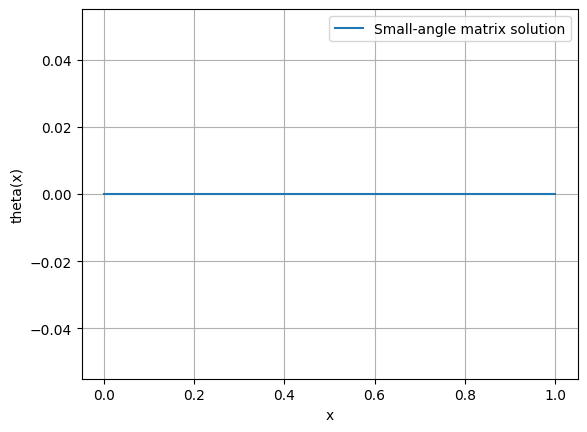

In [ ]:
# @title Direct Solution with small-angle aprox.
import numpy as np
import matplotlib.pyplot as plt

L = 1.0 # @param {"type":"number"}
N = 100 # @param {"type":"integer"}

# Example usage
alpha = 0.1

def small_angle_matrix_solution(alpha, L, N):
    dx = L / N
    x = np.linspace(0, L, N+1)

    # Unknowns are theta[1..N-1] → total N-1 unknowns
    M = N - 1
    A = np.zeros((M, M))

    # First row (i = 1)
    A[0, 0] = alpha * dx**2 - 2
    A[0, 1] = 1

    # Interior rows (i = 2..N-2)
    for i in range(1, M-1):
        A[i, i-1] = 1
        A[i, i]   = alpha * dx**2 - 2
        A[i, i+1] = 1

    # Last row (i = N-1)
    A[M-1, M-2] = 1
    A[M-1, M-1] = alpha * dx**2 - 1

    print("Matrix A:")
    print(A)

    # RHS
    b = np.zeros(M)
    #b[0] = 1e-6   # avoid trivial solution

    theta_inner = np.linalg.solve(A, b)

    # Build full theta
    theta = np.zeros(N+1)
    theta[1:N] = theta_inner
    theta[N] = theta[N-1]

    # Normalise
    #theta /= np.max(np.abs(theta))

    return x, theta

x, theta = small_angle_matrix_solution(alpha, L, N)

plt.plot(x, theta, label="Small-angle matrix solution")
plt.xlabel("x")
plt.ylabel("theta(x)")
plt.grid(True)
plt.legend()
plt.show()

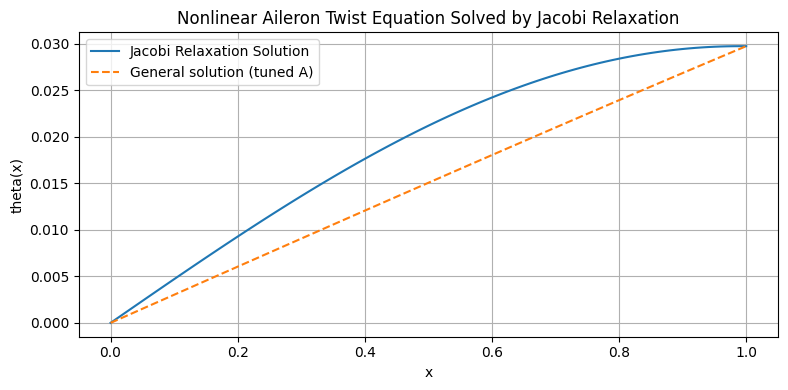

In [ ]:
# @title Jacobi Relation Solution (without small angle approx.)
L = 1.0 # @param {"type":"number"}
N = 100 # @param {"type":"integer"}

# Example usage
alpha = 0.1

import numpy as np
import matplotlib.pyplot as plt

def jacobi_aileron(alpha, L, N, max_iter=10_000, tol=1e-6):
    """
    Solve theta'' + alpha sin(theta) = 0 on [0, L]
    with theta(0) = 0, theta'(L) = 0 (theta_N = theta_{N-1})
    using Jacobi relaxation.
    """

    dx = L / N
    x = np.linspace(0.0, L, N + 1)

    # Non‑zero initial guess to avoid trivial solution
    theta_max = 0.1   # amplitude in radians (≈ 5.7 degrees)
    theta = theta_max * np.sin(0.5 * np.pi * x / L)

    theta_new = np.zeros_like(x)

    for k in range(max_iter):

        # Boundary at x=0
        theta_new[0] = 0.0

        # First interior node i = 1
        theta_new[1] = 0.5 * (
            theta[2] + alpha * dx**2 * np.sin(theta[1])
        )

        # Interior nodes i = 2..N-2
        for i in range(2, N - 1):
            theta_new[i] = 0.5 * (
                theta[i + 1] + theta[i - 1] + alpha * dx**2 * np.sin(theta[i])
            )

        # Final interior node i = N-1
        theta_new[N - 1] = theta[N - 2] + alpha * dx**2 * np.sin(theta[N - 1])

        # Neumann boundary: theta_N = theta_{N-1}
        theta_new[N] = theta_new[N - 1]

        # use under relaxation
        omega = 1.0
        theta_new[:] = (1-omega)*theta[:] + omega*theta_new[:]

        # Convergence check
        diff = np.max(np.abs(theta_new - theta))
        theta[:] = theta_new

        if diff < tol:
            print(f"Converged in {k+1} iterations, max change = {diff:.3e}")
            break

    return x, theta


x, theta = jacobi_aileron(alpha, L, N)

# Plot the solution
plt.figure(figsize=(8, 4))
plt.plot(x, theta, label="Jacobi Relaxation Solution")
plt.xlabel(r"$x$")
plt.ylabel(r"$\theta(x)$")
plt.title("Nonlinear Aileron Twist Equation Solved by Jacobi Relaxation")
plt.grid(True)
plt.legend()
plt.tight_layout()


def general_solution_from_jacobi(x, theta, alpha):
    """
    Given Jacobi solution (x, theta) and alpha,
    construct the tuned-A general solution:
        theta_gen(x) = theta(L) * sin(sqrt(alpha)*x) / sin(sqrt(alpha)*L)
    """
    L = x[-1]
    theta_L = theta[-1]
    sqrt_alpha = np.sqrt(alpha)

    # Avoid division by zero if sin(sqrt(alpha)*L) is extremely small
    denom = np.sin(sqrt_alpha * L)
    if np.abs(denom) < 1e-12:
        raise ValueError("sin(sqrt(alpha)*L) is too small; general solution undefined.")

    theta_gen = theta_L * np.sin(sqrt_alpha * x) / denom
    return theta_gen

# Example usage:
# Suppose you already computed Jacobi solution:
# x, theta = jacobi_aileron(alpha, L, N)

theta_gen = general_solution_from_jacobi(x, theta, alpha)

plt.plot(x, theta_gen, "--", label="General solution (tuned A)")
plt.xlabel("x")
plt.ylabel("theta(x)")
plt.grid(True)
plt.legend()
plt.show()

plt.show()

## Activity 2B - Neural Networks

**Problem:**

Consider the ODE from Activity 3A,

$$\frac{\mbox{d}x}{\mbox{d}t} = x^3 -x$$

in which a Neural Network is trained on data for $x(t)$ that is obtained by a RK4 solution of this initial value problem.

The Loss used for the training is not based on a direct comparison of the learned ODE with the true ODE, as this approach is only useful when the underlying ODE is **unknown**.

If $x(t_f)$ is the solution that would come from the true ODE,

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f(t,x(t)) \mbox{d}t,$$

then the solution from the **Neural ODE** is

$$ x(t_f) = x(t_0) + \int^{t_f}_{t_0} f_\theta(t,x(t)) \mbox{d}t,$$

where $f_\theta$ is the output of a neural network with input $t$, and $x(t)$.

Forward solution of the system requires the temporal integration of output of the neural network, with loss based on the how well the resulting final position $x(t_f)$ matches the training data,

$$\mathcal{L}(x(t_f), y(t_f)).$$

**Task:**
1. Use the provided RK4 function in Activity 3A to generate trajectories for:
* Training ICs:
[ [-0.9, -0.75, -0.5, -0.2, 0] ]
* Test ICs:
[ [-1.2, -1.0, -0.3, 0.2, 0.8] ]
* Run the Neural Network from Activity 3A with your modified Traing data and answer the following Questions
    - Why is it important to include both negative and positive ICs?
    - What happens if all ICs are clustered near zero?
    - How does the time step affect the smoothness of the data?
2. Look at the structure of the Neural ODE and answer the following:
   - Why does the loss compare solutions, not derivatives?
   - Why is this useful when the true ODE is unknown?
   - Why is training slower than the plain NN?
3. Build a Plain NN Model:
$$ (t_i, x_i) \mapsto x_{i+1}
 $$
   Architecture suggestion
    - Input: 2
    - Hidden: 2 layers × 64 units
    - Activation: tanh
    - Output: 1
* Use your network to explore the following.
    * What does this NN actually learn?
    * Does it learn the vector field $ f(x) $?
    * Does it learn the flow map $ x(t+\Delta t) $?
    * What happens if you change the time step?
    * Can this NN extrapolate beyond the training time window?

4. What are the potential benefits of a Neural ODE when compared to a plain NN?

**Hints:**
* AI should be able to do a good jobs of generating most of the code needed to set up a NN in PyTorch.
* You can alsos find similar examples in Notebooks 10.2-10.3.

## Activity 3B — Understanding PINNs for the Damped Pendulum

**Problem:**
In Activity 4A, we demonstrated that a Physics‑Informed Neural Network (PINN) with sinusoidal activation functions could successfully learn the motion of a damped pendulum governed by:
$$ \theta^{\prime\prime}(t) + 2\beta\,\theta^\prime(t) + \omega_0^2\,\theta(t) = 0,
 $$
using:
* a known friction coefficient $ \beta $,
* initial condition loss enforcing $ \theta(0) $ and $ \theta^\prime(0) $,
* limited data points for $ \theta(t) $,
* and a physics loss enforcing the ODE residual.
The total loss was a weighted combination:
$$ \mathcal{L} =
\lambda_{\text{phys}} \mathcal{L}_{\text{phys}} +
\lambda_{\text{IC}} \mathcal{L}_{\text{IC}} +
\lambda_{\text{data}} \mathcal{L}_{\text{data}}.
 $$
This activity asks you to explore how varying these weights affects the learned solution.

**Task:**

1. Vary the physics loss weight `lambda_phys`. What happens to the solution when you make it:
* Very small (e.g., $ 10^{-3} $)
* Moderate (e.g., $ 1 $)
* Very large (e.g., $ 10^3 $)

    Explain how the pendulum motion changes and why.

2. How important is the data loss term `lambda_data` when only a few data points are available?
Consider:
* Does the PINN still follow the correct oscillatory decay?
* Does the solution drift or flatten out?
* Does the network rely more heavily on physics when data is sparse?

3. How important is the initial condition loss `lambda_IC`?
Discuss:
* What happens if $\lambda_{\text{IC}}$ is too small?
* Does the solution start at the wrong angle or wrong velocity?
* How does this affect the entire trajectory?

4. When the friction coefficient $\beta$ is known, why does the physics term strongly constrain the solution?
Reflect on:
* How the ODE residual enforces the correct damping behaviour.
* Why the PINN can recover the full trajectory even with limited data.
* Why sinusoidal activations help represent oscillatory solutions.

6. Compare the PINN to a plain NN trained only on the sparse data points.
Discuss:
* Which model extrapolates better in time?
* Which model respects the correct decay rate?
* Which model produces physically plausible oscillations?

**Hints:**

* you can achieve a plain NN but turning of all loss terms exept the data.
* use the **Final code** with Sin activation from in Activity 4A.


## Activity 4B — PDE Classification and Marching Solutions

**Problem:**
Understanding the classification of Partial Differential Equations (PDEs) is crucial for choosing appropriate numerical solution methods. Different classifications (elliptic, parabolic, hyperbolic) imply different characteristics of the solution and the necessary information (initial vs. boundary conditions).

**Task:**

1.  **PDE Classification**: Classify the following second-order linear PDEs into elliptic, parabolic, or hyperbolic types based on the coefficients of its highest-order derivatives. For each, explain your reasoning.

    *   $$ \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = 0 $$
    *   $$ \frac{\partial u}{\partial t} - k \frac{\partial^2 u}{\partial x^2} = G(x,t) $$ (where $k > 0$ and $G(x,t)$ is a source term)
    *   $$ \frac{\partial^2 u}{\partial t^2} - c^2 \frac{\partial^2 u}{\partial x^2} = F(x,t) $$ (where $c \neq 0$ and $F(x,t)$ is an external force term)
    *   $$ \frac{\partial^2 u}{\partial x^2} + 2 \frac{\partial^2 u}{\partial x ∂ y} + \frac{\partial^2 u}{\partial y^2} = h(x,y) $$


2.  **Marching Solutions for BVPs**: Explain when a PDE's classification will require a "time-like marching solution" for a Boundary Value Problem (BVP). Discuss how the nature of the information propagation (or lack thereof) for each PDE type dictates whether a marching method (stepping forward in one dimension) is suitable, especially in the context of BVPs.

3.  **Space-Marching IVP Example**: Provide at least one example of a physical problem that is an Initial Value Problem (IVP) where the marching direction is *space* instead of time. Describe the PDE, the initial conditions (which will be specified along a spatial boundary), and why it behaves like an IVP despite evolving in a spatial dimension.

**Hints:**

*   For classification, consider the general form $A u_{xx} + B u_{xy} + C u_{yy} = D(x,y,t)$ and the discriminant $B^2 - 4AC$.
*   Think about how information (e.g., disturbances, heat, waves) propagates through the domain for each PDE type.
*   For space-marching examples, look for problems where conditions are known at one spatial extreme and you want to find the solution deeper into the domain, without conditions at the other end of that spatial dimension.

# ⬛ Revision and home study

Finish incomplete B activities before attempting the questions below. Answers should use
units, numerical evidence and physical interpretation—not only method names.


## 📝 Activity 5 — Test-style short problems

1.  In the direct finite difference solution of a BVP like $y''=0$, why might increasing the number of discretization points ($N$) not always lead to a more 'accurate' visually different solution if the analytical solution is linear?
2.  What is the primary condition for Jacobi relaxation to converge when solving $y'' = 0$ numerically?
3.  For the Neural ODE learning $dx/dt = x^3 - x$, why is it crucial to train with initial conditions that span both positive and negative values of $x$?
4.  Explain why the loss function for a Neural ODE typically compares the integrated solutions rather than the derivatives, especially when the true ODE is unknown.
5.  How does non-dimensionalization of the governing ODE, such as $\tau = \omega_0 t$ in the damped pendulum example, help improve the training stability and performance of a Physics-Informed Neural Network (PINN)?
6.  When training a PINN for an oscillatory system, what advantage does a `Sin` activation function offer over a `Tanh` activation function, particularly for extrapolation?
7.  Classify the PDE $u_{tt} + 2u_{xy} - u_{yy} = 0$ as elliptic, parabolic, or hyperbolic, and state your reasoning.
8.  For which types of PDEs (elliptic, parabolic, or hyperbolic) is a 'time-like marching solution' generally suitable for a Boundary Value Problem (BVP), and why?
9.  Briefly describe a physical example of an Initial Value Problem (IVP) where the marching direction is a spatial dimension instead of time.
10. Compare the generalization capabilities of a Neural ODE versus a plain neural network trained to predict $x(t+\Delta t)$ from $x(t)$ for varying initial conditions. Which typically performs better for unseen initial conditions over longer time horizons, and why?

## 🧪 Activity 6 — Integrated method-selection challenge

For each scenario, identify the most appropriate numerical method(s) from the workbook content (e.g., Direct Finite Difference, Jacobi Relaxation, Neural ODE, PINN, time-marching, global solver) and explain your reasoning. Also, state one key aspect you would measure, assume, or critically evaluate to validate your choice.

1.  **Steady-State Deflection of a Flexible Beam**: You need to find the static deflection profile of a long, thin beam clamped at both ends, subjected to a distributed load. The governing equation is a fourth-order linear BVP (which can be reduced to a system of second-order equations), and you require a solution that captures global behavior accurately without iteration.
2.  **Learning Chaotic Dynamics from Sparse Data**: You have a limited set of noisy time-series data from a non-linear system exhibiting chaotic behavior. You need to develop a model that can accurately predict the system's trajectory and generalize well beyond the training data points, even for initial conditions slightly outside the training range. The exact governing equations are unknown.
3.  **Non-linear Heat Conduction with Radiation**: You are modeling steady-state heat transfer in a solid where the heat conductivity depends on temperature, and heat loss at the surface includes a non-linear radiation term ($T^4$). Conditions are fixed at the boundaries. You need an iterative method to find the temperature distribution.
4.  **Damped Oscillator Extrapolation**: You are given a small set of measurements for a heavily damped oscillatory system and its initial state. You need a model that can accurately predict its behavior far beyond the last data point and adhere strictly to the known physics of the system, even if the data is sparse and potentially noisy. The natural frequency ($\omega_0$) is very high compared to the damping coefficient ($\beta$).
5.  **Simulating 2D Unsteady Heat Diffusion**: You are tasked with predicting how temperature evolves over time in a 2D plate given an initial temperature distribution and fixed boundary temperatures. You need a method that can efficiently step the solution forward in time.
6.  **Analyzing Aerodynamic Flow in a Nozzle**: You are simulating steady, incompressible flow through a converging-diverging nozzle. You know the conditions at the inlet, and the governing equations are parabolic in the flow direction. You need to find the pressure and velocity profiles throughout the nozzle, but no information is available or needed at the outlet.


## ✅ Week 10 completion checklist

- [ ] I can formulate and solve linear and nonlinear Boundary Value Problems (BVPs) using direct finite difference methods.
- [ ] I can apply iterative methods (e.g., Jacobi relaxation) to solve discrete BVP systems and analyze their convergence.
- [ ] I can evaluate the order of accuracy of finite difference schemes for ODEs and their boundary conditions.
- [ ] I can understand the principles of Neural Ordinary Differential Equations (Neural ODEs) and their application in learning ODE dynamics from data.
- [ ] I can explain why Neural ODE loss typically compares solutions, not derivatives, and how this is useful when the true ODE is unknown.
- [ ] I can compare the generalization capabilities and training characteristics of Neural ODEs with plain neural networks.
- [ ] I can formulate Physics-Informed Neural Networks (PINNs) by integrating physics-based loss terms, initial conditions, and data.
- [ ] I can analyze the impact of non-dimensionalization on PINN performance and stability, particularly for oscillatory systems.
- [ ] I can explain the advantages of `Sin` activation functions over `Tanh` in PINNs for oscillatory problems and extrapolation.
- [ ] I can classify second-order linear Partial Differential Equations (PDEs) as elliptic, parabolic, or hyperbolic and explain my reasoning.
- [ ] I can determine when a PDE's classification necessitates a 'time-like marching solution' for BVPs and provide examples of space-marching IVPs.
- [ ] I can select appropriate numerical methods (e.g., Direct Finite Difference, Jacobi Relaxation, Neural ODE, PINN, time-marching, global solver) for various engineering scenarios and justify my choice with validation criteria.

# 📚 References and data provenance

Method definitions and APIs follow the official NumPy and SciPy documentation referenced
in Notes 10.1–10.4. All examples are synthetic,
deterministic and generated in code. They expose numerical behaviour and are not
measurements for engineering design.

# 🤖 AI acknowledgement

Generative AI assisted with drafting, code development and editorial review. Activities,
numerical behaviour and tutor solutions were checked for alignment with the Week 9 notes
and unit learning outcomes.
